# **Asthma Detection**

In [2]:
!pip install torch_geometric efficientnet_pytorch
!pip install audiomentations librosa matplotlib scikit-learn networkx scipy audiomentations


# **Proposed Model for Asthma**

Device: cpu


[DATA] samples=1211, feat_dim=422, classes=[np.str_('Bronchial'), np.str_('asthma'), np.str_('copd'), np.str_('healthy'), np.str_('pneumonia')]
[PIPE] Using PCA n_components=200, top_k=15
[PIPE] Graph nodes 1211, edges 18165
[PIPE] Training ensemble ...
[seed 42] Epoch 001 loss=1.0712 val_acc=0.4074
[seed 42] Epoch 010 loss=0.4126 val_acc=0.7366
[seed 42] Epoch 020 loss=0.2685 val_acc=0.7860
[seed 42] Epoch 030 loss=0.2472 val_acc=0.8066
[seed 42] Epoch 040 loss=0.1478 val_acc=0.8560
[seed 42] Epoch 050 loss=0.0976 val_acc=0.8642
[seed 42] Epoch 060 loss=0.0879 val_acc=0.8765
[seed 42] Epoch 070 loss=0.0544 val_acc=0.8642
[seed 42] Epoch 080 loss=0.0342 val_acc=0.8560
[seed 42] Early stopping at epoch 83. best_val=0.8765
[seed 77] Epoch 001 loss=1.1081 val_acc=0.3951
[seed 77] Epoch 010 loss=0.4237 val_acc=0.6461
[seed 77] Epoch 020 loss=0.2791 val_acc=0.7490
[seed 77] Epoch 030 loss=0.2495 val_acc=0.7572
[seed 77] Epoch 040 loss=0.1397 val_acc=0.7984
[seed 77] Epoch 050 loss=0.0950 va

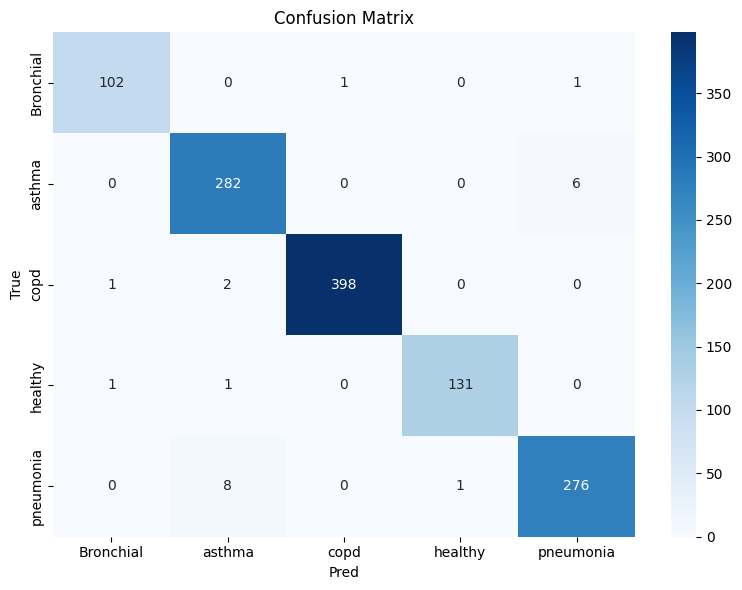

Saved asthma_v7_confusion.png


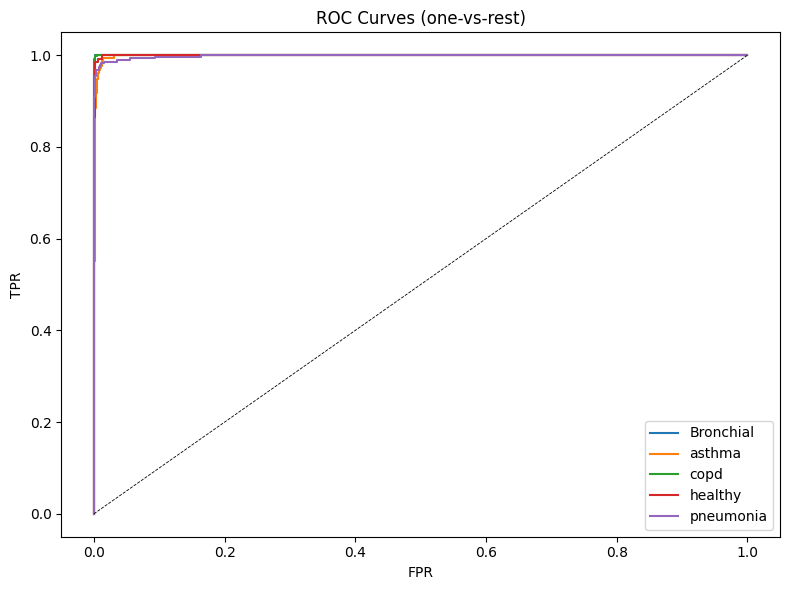

Saved asthma_v7_roc.png

Overall metrics:
Accuracy: 0.9818  Precision: 0.9819  Recall: 0.9818  F1: 0.9819  AUC: 0.9993

Class-wise Test Performance:
  Bronchial: Precision=0.981, Recall=0.981, F1=0.981
  asthma: Precision=0.962, Recall=0.979, F1=0.971
  copd: Precision=0.997, Recall=0.993, F1=0.995
  healthy: Precision=0.992, Recall=0.985, F1=0.989
  pneumonia: Precision=0.975, Recall=0.968, F1=0.972
[PIPE] t-SNE embedding visualization ...


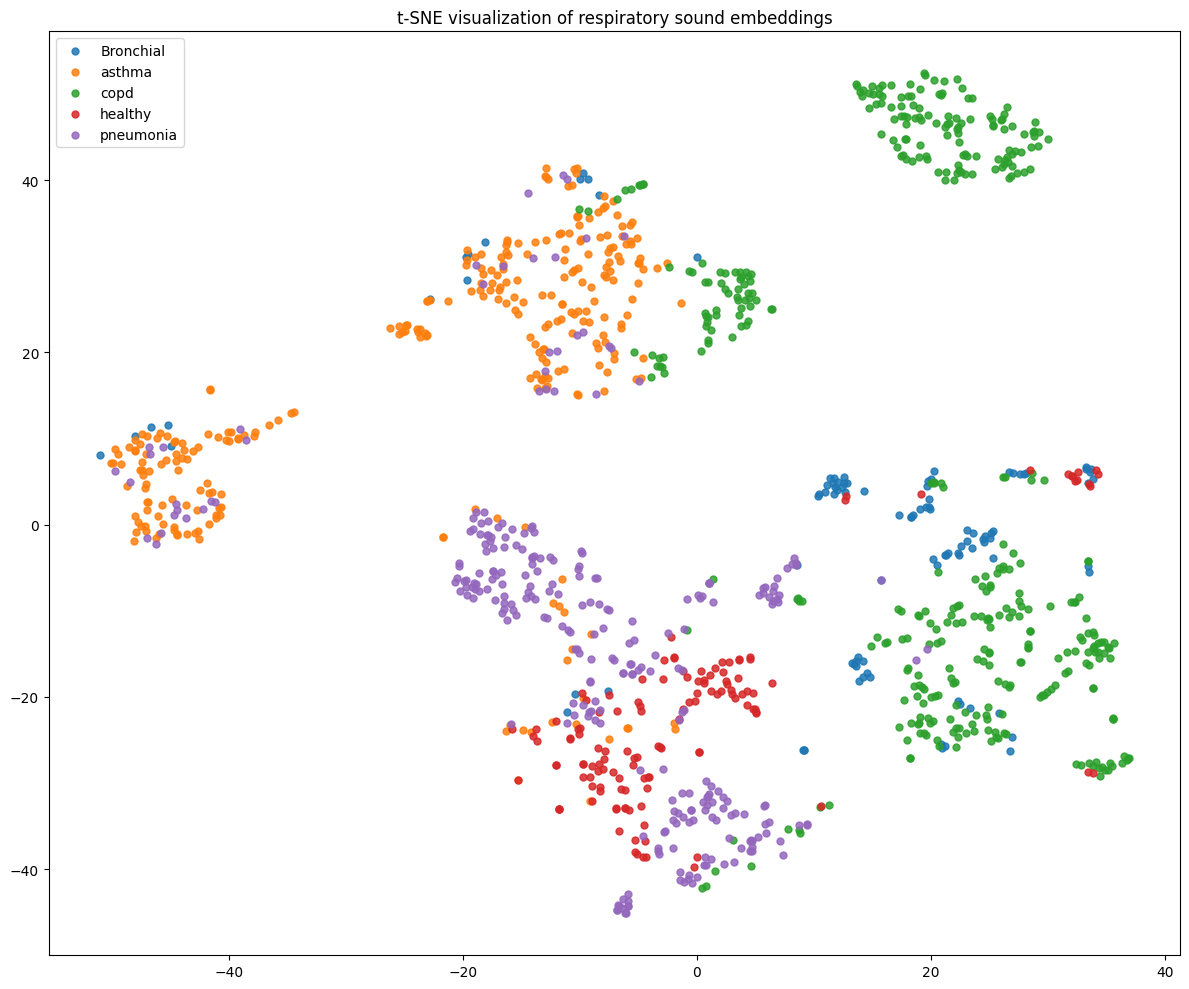

Saved asthma_v7_tsne.png
[PIPE] Grad-CAM (saliency) examples ...


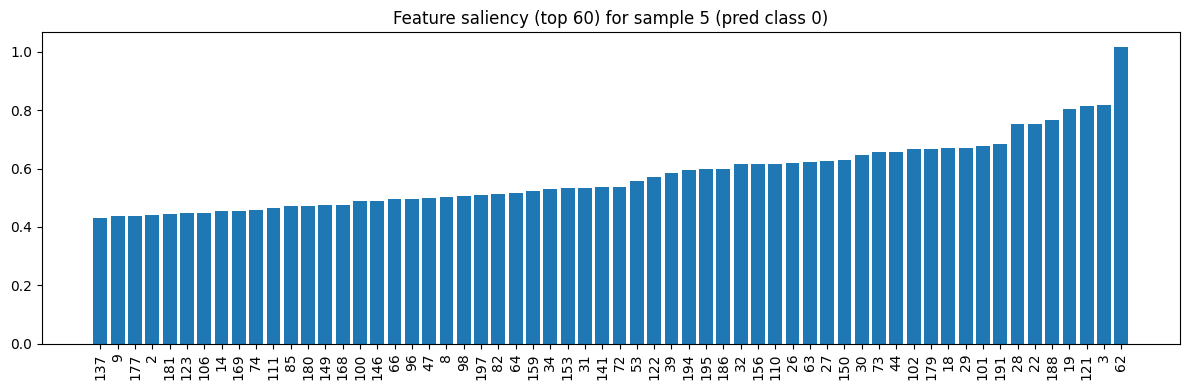

Saved asthma_v7_sample5.png


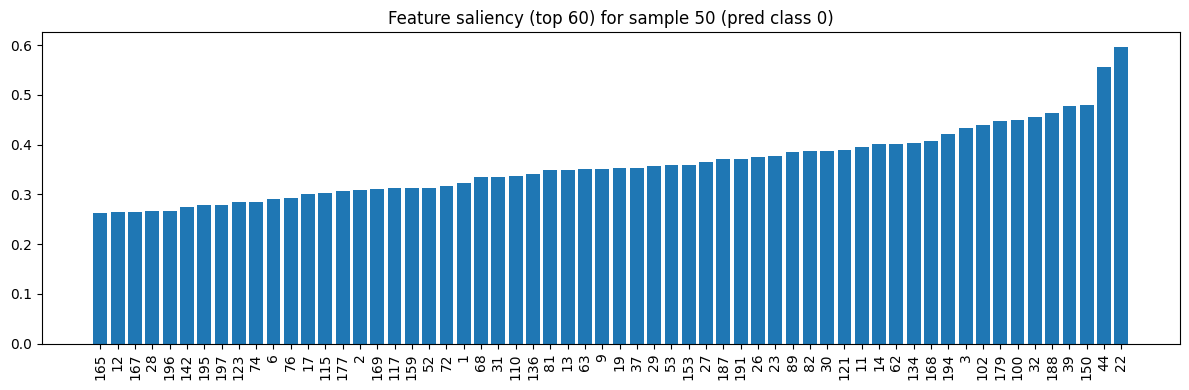

Saved asthma_v7_sample50.png


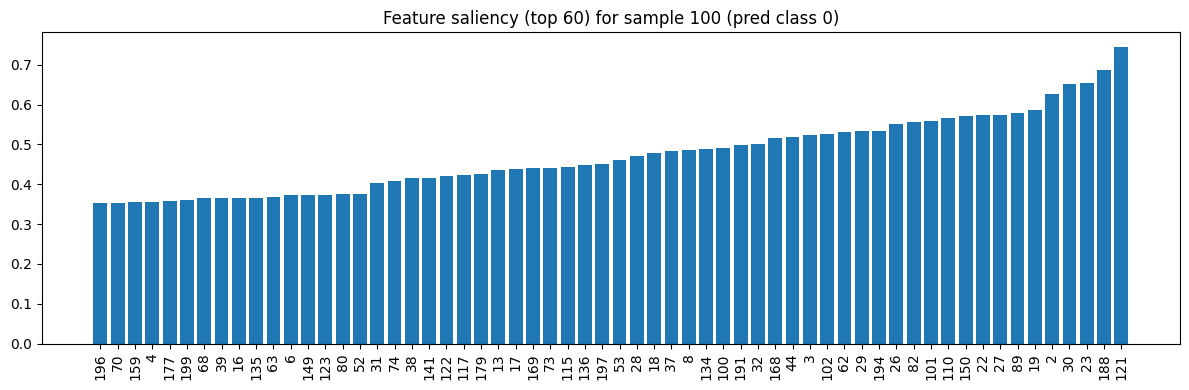

Saved asthma_v7_sample100.png
[PIPE] Aggregating per-class saliency ...


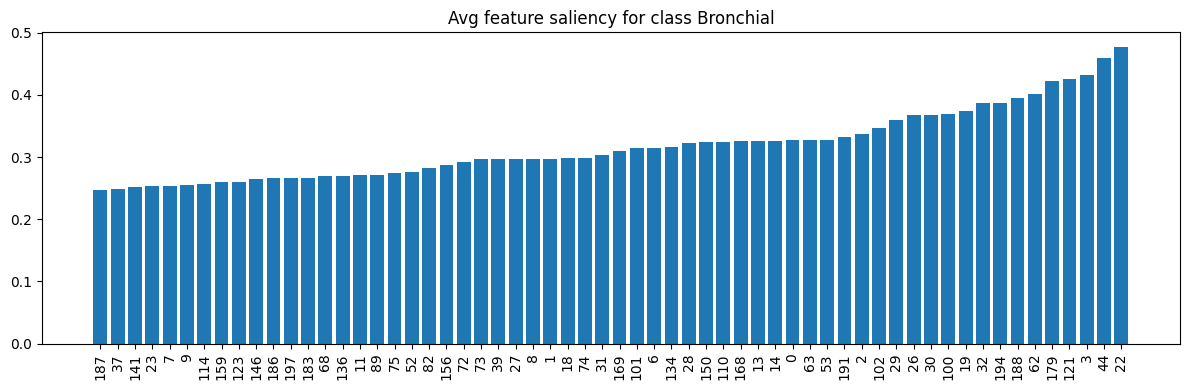

Saved asthma_v7_Bronchial.png


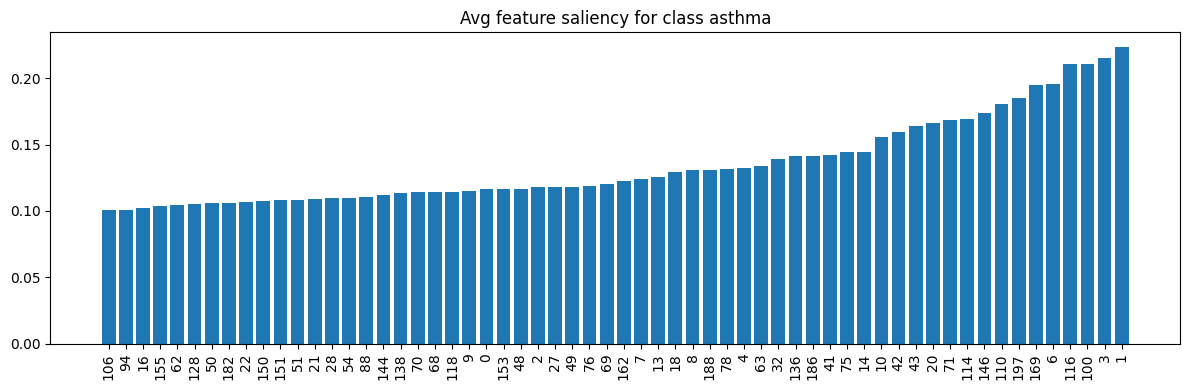

Saved asthma_v7_asthma.png


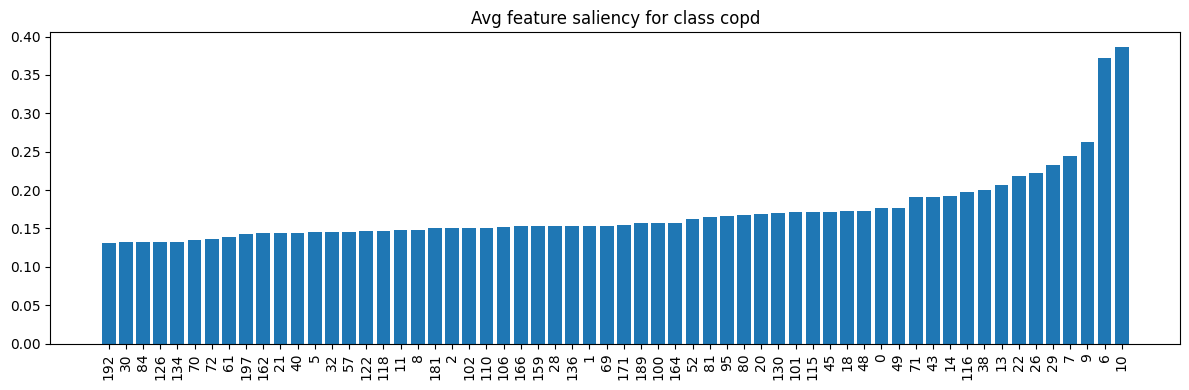

Saved asthma_v7_copd.png


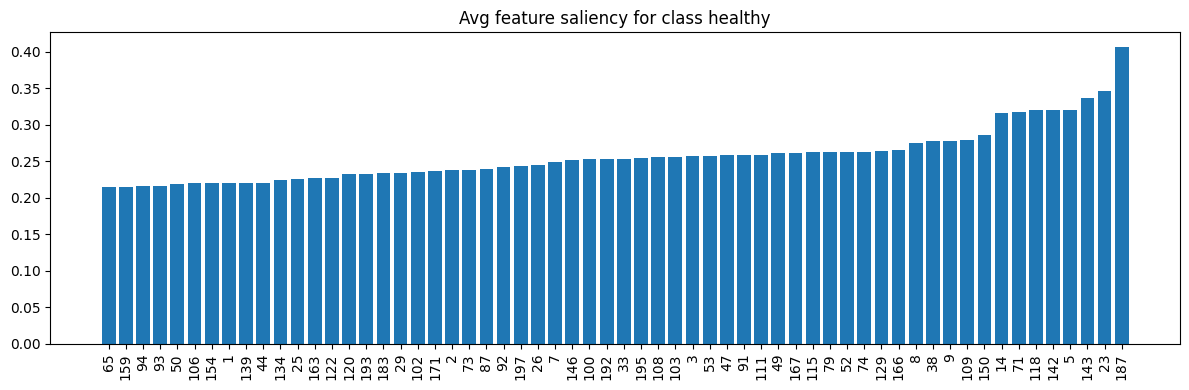

Saved asthma_v7_healthy.png


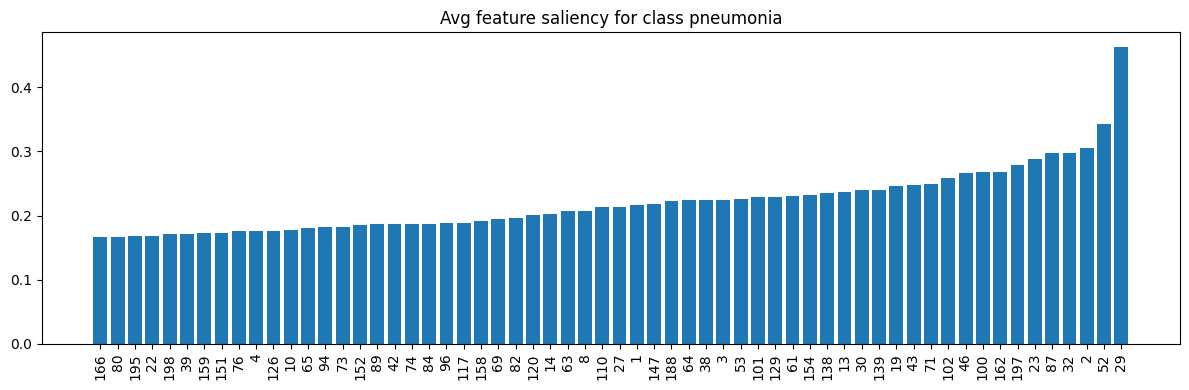

Saved asthma_v7_pneumonia.png
Saved asthma_v7_model_seed42.pt
Saved asthma_v7_model_seed77.pt
Saved asthma_v7_model_seed123.pt
Saved asthma_v7_model_seed2025.pt
Saved meta-model for stacking
[PIPE] Done. Plots saved with prefix: asthma_v7
Total time (s): 974


In [ ]:
# ===============================================================
# Asthma Detection v7 — Attempt to exceed prior best (>98%)
# Full training + ensemble + stacking + visualizations
# ===============================================================
# Usage: Paste into Colab or run as a .py. Set data_root to your dataset path.
# Dataset structure: data_root/<class_name>/*.wav
# ===============================================================

import os, gc, math, random, time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

# Audio & ML
import librosa
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression

# PyTorch / PyG
import torch
import torch.nn.functional as F
from torch.cuda.amp import autocast, GradScaler
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GATConv, TransformerConv, LayerNorm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---------------------------
# Config (tune these values)
# ---------------------------
data_root = "/content/drive/MyDrive/Asthma Detection Dataset"  # <<-- change to your path
best_pca = 200      # previous good config
best_k = 15         # previous good config
ensemble_seeds = [42, 77, 123, 2025]
epochs = 240
hidden_dim = 256
dropout = 0.35
use_focal = True    # try focal loss (good for class imbalance)
use_class_weights = True
stacking_meta = True  # train logistic regression on val predictions
do_tsne = True
save_plots_prefix = "asthma_v7"
random_seed = 42

# set seeds for reproducibility
np.random.seed(random_seed)
torch.manual_seed(random_seed)
random.seed(random_seed)

# ---------------------------
# Utility: Focal Loss
# ---------------------------
class FocalLoss(torch.nn.Module):
    def __init__(self, gamma=2.0, weight=None, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.weight = weight
        self.reduction = reduction
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction='none')
        p_t = torch.exp(-ce)
        loss = ((1 - p_t) ** self.gamma) * ce
        if self.reduction == 'mean':
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        else:
            return loss

# ---------------------------
# Audio feature extraction
# ---------------------------
def extract_features(path, sr=16000, n_mfcc=40, min_dur_s=0.2):
    try:
        y, sr = librosa.load(path, sr=sr, mono=True)
        if y is None or len(y) < sr * min_dur_s:
            return None
        # pre-emphasis & normalize
        y = np.append(y[0], y[1:] - 0.97 * y[:-1])
        y = librosa.util.normalize(y)
        n_fft, hop = 1024, 256

        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop)
        mfcc_d = librosa.feature.delta(mfcc)
        mfcc_dd = librosa.feature.delta(mfcc, order=2)
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr, n_fft=n_fft, hop_length=hop)
        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
        tonnetz = None
        try:
            tonnetz = librosa.feature.tonnetz(y=librosa.effects.harmonic(y), sr=sr)
        except Exception:
            tonnetz = np.zeros((6, max(1, mfcc.shape[1])))
        zcr = librosa.feature.zero_crossing_rate(y)
        rms = librosa.feature.rms(y=y)

        def pool(m): return np.concatenate([np.mean(m, axis=1), np.std(m, axis=1)])

        feat = np.concatenate([
            pool(mfcc), pool(mfcc_d), pool(mfcc_dd),
            pool(mel), pool(chroma), pool(contrast),
            pool(tonnetz), pool(zcr), pool(rms)
        ])
        return feat.astype(np.float32)
    except Exception as e:
        print(f"[WARN] feat fail {os.path.basename(path)}: {e}")
        return None

# ---------------------------
# Build dataset
# ---------------------------
def build_dataset(root):
    if not os.path.isdir(root):
        raise ValueError("Data root not found: " + root)
    classes = sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))])
    if len(classes) == 0:
        raise ValueError("No class subfolders found under data root.")
    feats, labels, paths = [], [], []
    for c in classes:
        cls_dir = os.path.join(root, c)
        files = sorted([f for f in os.listdir(cls_dir) if f.lower().endswith('.wav')])
        for f in tqdm(files, desc=f"Extract {c}", leave=False):
            p = os.path.join(cls_dir, f)
            v = extract_features(p)
            if v is not None:
                feats.append(v)
                labels.append(c)
                paths.append(p)
    if len(feats) == 0:
        raise RuntimeError("No features extracted.")
    # fix ragged lengths
    lengths = [f.shape[0] for f in feats]
    if len(set(lengths)) > 1:
        most_common = max(set(lengths), key=lengths.count)
        new = []
        for f in feats:
            if f.shape[0] < most_common:
                new.append(np.pad(f, (0, most_common - f.shape[0])))
            else:
                new.append(f[:most_common])
        X = np.vstack(new).astype(np.float32)
    else:
        X = np.vstack(feats).astype(np.float32)
    le = LabelEncoder()
    y = le.fit_transform(labels)
    print(f"[DATA] samples={X.shape[0]}, feat_dim={X.shape[1]}, classes={list(le.classes_)}")
    return X, y, paths, le

# ---------------------------
# Graph builder (cosine-based kNN graph)
# ---------------------------
def build_graph(X, y, top_k=20):
    from sklearn.metrics.pairwise import cosine_similarity
    sim = cosine_similarity(X)
    np.fill_diagonal(sim, 0)
    n = sim.shape[0]
    edges = []
    for i in range(n):
        k = min(top_k, n-1)
        idx = np.argsort(sim[i])[-k:]
        for j in idx:
            edges.append((i, j))
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    data = Data(x=torch.tensor(X, dtype=torch.float32), edge_index=edge_index, y=torch.tensor(y, dtype=torch.long))
    return data

# ---------------------------
# Model: Hybrid GCN+GAT+Transformer
# ---------------------------
class HybridAudioGNN(torch.nn.Module):
    def __init__(self, in_dim, hidden=256, out_dim=5, drop=0.35):
        super().__init__()
        self.gcn = GCNConv(in_dim, hidden)
        self.gat = GATConv(hidden, hidden, heads=2, concat=False)
        self.trans = TransformerConv(hidden, hidden)
        self.alpha = torch.nn.Parameter(torch.tensor(0.5))
        self.norm = LayerNorm(hidden)
        self.fc = torch.nn.Sequential(
            torch.nn.Linear(hidden, hidden // 2),
            torch.nn.ReLU(),
            torch.nn.Dropout(drop),
            torch.nn.Linear(hidden // 2, out_dim)
        )
    def forward(self, x, e, return_embedding=False):
        x1 = F.relu(self.gcn(x, e))
        x2 = F.relu(self.gat(x1, e))
        x3 = F.relu(self.trans(x2, e))
        emb = self.norm((x1 + x2 + self.alpha * x3) / 2)
        logits = self.fc(emb)
        if return_embedding:
            return logits, emb
        return logits

# ---------------------------
# Train single model (AMP, early stop, class weights/focal)
# ---------------------------
def train_model(graph, seed=42, epochs=200, lr=1e-3, patience=30, verbose=False):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    N = graph.x.size(0)
    idx = np.arange(N)
    tr, va = train_test_split(idx, test_size=0.2, stratify=graph.y.cpu().numpy(), random_state=seed)
    train_mask = torch.zeros(N, dtype=torch.bool); val_mask = torch.zeros(N, dtype=torch.bool)
    train_mask[tr] = True; val_mask[va] = True

    num_classes = int(graph.y.max().item() + 1)
    model = HybridAudioGNN(graph.x.size(1), hidden=hidden_dim, out_dim=num_classes, drop=dropout).to(device)
    g = graph.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=30, T_mult=1)
    scaler = GradScaler()

    # class weights if requested
    if use_class_weights:
        from sklearn.utils.class_weight import compute_class_weight
        cw = compute_class_weight('balanced', classes=np.arange(num_classes), y=graph.y.cpu().numpy())
        cw_t = torch.tensor(cw, dtype=torch.float).to(device)
    else:
        cw_t = None

    criterion = FocalLoss(gamma=2.0, weight=cw_t) if use_focal else torch.nn.CrossEntropyLoss(weight=cw_t)

    best_val = -1.0; best_state = None; patience_ctr = 0
    for ep in range(1, epochs+1):
        model.train()
        opt.zero_grad(set_to_none=True)
        with autocast():
            out = model(g.x, g.edge_index)
            loss = criterion(out[train_mask], g.y[train_mask])
        scaler.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        scaler.step(opt); scaler.update()
        sched.step()

        # validation
        model.eval()
        with torch.no_grad():
            logits = model(g.x, g.edge_index)
            preds = logits.argmax(dim=1)
            val_acc = (preds[val_mask] == g.y[val_mask]).float().mean().item()

        if val_acc > best_val + 1e-6:
            best_val = val_acc; best_state = model.state_dict(); patience_ctr = 0
        else:
            patience_ctr += 1

        if verbose and (ep % 10 == 0 or ep == 1):
            print(f"[seed {seed}] Epoch {ep:03d} loss={loss.item():.4f} val_acc={val_acc:.4f}")
        if patience_ctr >= patience:
            if verbose: print(f"[seed {seed}] Early stopping at epoch {ep}. best_val={best_val:.4f}")
            break

        # cleanup
        gc.collect(); torch.cuda.empty_cache()

    # restore best
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        logits = model(g.x, g.edge_index)
        probs = F.softmax(logits, dim=1).cpu().numpy()
        preds = probs.argmax(axis=1)
        true = g.y.cpu().numpy()

    return dict(preds=preds, probs=probs, true=true, val=best_val, model=model)

# ---------------------------
# Ensemble training + weighted averaging + stacking
# ---------------------------
def train_ensemble(graph, seeds=ensemble_seeds, epochs_local=epochs, verbose=True):
    results = []
    for s in seeds:
        res = train_model(graph, seed=s, epochs=epochs_local, verbose=verbose)
        results.append(res)
    probs_stack = np.stack([r['probs'] for r in results], axis=0)  # (M, N, C)
    val_scores = np.array([r['val'] for r in results])
    # weights: shift so positive, then normalize
    weights = val_scores - val_scores.min() + 1e-6
    weights = weights / weights.sum()
    avg_probs = np.tensordot(weights, probs_stack, axes=(0,0))  # (N, C)
    final_preds = avg_probs.argmax(axis=1)
    true = results[0]['true']  # same true for all
    models = [r['model'] for r in results]

    # stacking: train meta-classifier on out-of-fold val predictions
    meta_model = None
    if stacking_meta:
        # Build OOF predictions by retraining on different seeds' val sets is expensive.
        # Simpler stacking: use each model's soft probs as features, train LR on validation split.
        X_meta = np.hstack([r['probs'] for r in results])  # (N, M*C)
        X_tr, X_va, y_tr, y_va = train_test_split(X_meta, true, test_size=0.2, stratify=true, random_state=12345)
        lr = LogisticRegression(max_iter=2000, multi_class='multinomial')
        lr.fit(X_tr, y_tr)
        meta_probs = lr.predict_proba(X_meta)
        meta_preds = meta_probs.argmax(axis=1)
        # choose whether stacking improved val f1; if improved, use stacking predictions
        if f1_score(true, meta_preds, average='weighted') >= f1_score(true, final_preds, average='weighted'):
            final_preds = meta_preds
            avg_probs = meta_probs
            meta_model = lr

    return final_preds, avg_probs, true, models, val_scores, meta_model

# ---------------------------
# Visualization functions
# ---------------------------
def visualize_confusion(cm, le, prefix):
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title("Confusion Matrix")
    plt.ylabel("True")
    plt.xlabel("Pred")
    fn = f"{prefix}_confusion.png"
    plt.tight_layout(); plt.savefig(fn, dpi=300); plt.show()
    print(f"Saved {fn}")

def visualize_roc(y_true, y_prob, le, prefix):
    y_bin = label_binarize(y_true, classes=np.arange(len(le.classes_)))
    plt.figure(figsize=(8,6))
    for i, cls in enumerate(le.classes_):
        try:
            fpr, tpr, _ = roc_curve(y_bin[:,i], y_prob[:,i])
            plt.plot(fpr, tpr, label=f"{cls}")
        except Exception:
            continue
    plt.plot([0,1],[0,1],'k--',linewidth=0.6)
    plt.title("ROC Curves (one-vs-rest)")
    plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend()
    fn = f"{prefix}_roc.png"
    plt.tight_layout(); plt.savefig(fn, dpi=300); plt.show()
    print(f"Saved {fn}")

def print_classwise(y_true, y_pred, le):
    report = classification_report(y_true, y_pred, target_names=le.classes_, digits=3, output_dict=True)
    print("\nClass-wise Test Performance:")
    for cls in le.classes_:
        p = report[cls]['precision']; r = report[cls]['recall']; f = report[cls]['f1-score']
        print(f"  {cls}: Precision={p:.3f}, Recall={r:.3f}, F1={f:.3f}")

# t-SNE embeddings visualization
def visualize_tsne(model, graph, le, prefix, perplexity=30, n_samples=None):
    model.eval()
    g = graph.to(device)
    with torch.no_grad():
        try:
            logits, emb = model(g.x, g.edge_index, return_embedding=True)
        except TypeError:
            x1 = F.relu(model.gcn(g.x, g.edge_index))
            x2 = F.relu(model.gat(x1, g.edge_index))
            x3 = F.relu(model.trans(x2, g.edge_index))
            emb = model.norm((x1 + x2 + model.alpha * x3) / 2)
        emb = emb.cpu().numpy()
    n = emb.shape[0]
    if n_samples is not None and n_samples < n:
        idxs = np.random.choice(n, n_samples, replace=False)
        emb2d = TSNE(n_components=2, perplexity=min(perplexity, max(5, n_samples-1)), random_state=42).fit_transform(emb[idxs])
        labels_plot = graph.y.cpu().numpy()[idxs]
    else:
        emb2d = TSNE(n_components=2, perplexity=min(perplexity, max(5, n-1)), random_state=42).fit_transform(emb)
        labels_plot = graph.y.cpu().numpy()
    plt.figure(figsize=(12,10))
    for i, cls in enumerate(le.classes_):
        idxs = np.where(labels_plot == i)[0]
        plt.scatter(emb2d[idxs,0], emb2d[idxs,1], s=25, alpha=0.85, label=cls)
    plt.legend(); plt.title("t-SNE visualization of respiratory sound embeddings")
    fn = f"{prefix}_tsne.png"
    plt.tight_layout(); plt.savefig(fn, dpi=300); plt.show()
    print(f"Saved {fn}")

# Grad-CAM style saliency per-sample and aggregated per-class
def grad_cam_saliency(model, graph, sample_idx=0, top_k_features=60, prefix="saliency"):
    model.eval()
    g = graph.to(device)
    x = g.x.clone().detach().to(device).requires_grad_(True)
    out = model(x, g.edge_index)
    pred_class = out[sample_idx].argmax().item()
    score = out[sample_idx, pred_class]
    model.zero_grad()
    score.backward(retain_graph=False)
    grads = x.grad.detach().abs().cpu().numpy()  # (N, F)
    # feature importance aggregated across nodes
    feat_imp = grads.sum(axis=0)
    topk = min(top_k_features, feat_imp.size)
    top_idx = np.argsort(feat_imp)[-topk:]
    plt.figure(figsize=(12,4))
    plt.bar(range(len(top_idx)), feat_imp[top_idx])
    plt.xticks(range(len(top_idx)), top_idx, rotation=90)
    plt.title(f"Feature saliency (top {topk}) for sample {sample_idx} (pred class {pred_class})")
    fn = f"{prefix}_sample{sample_idx}.png"
    plt.tight_layout(); plt.savefig(fn, dpi=300); plt.show()
    print(f"Saved {fn}")
    return feat_imp

def aggregate_class_saliency(model, graph, le, prefix="saliency_class"):
    model.eval()
    g = graph.to(device)
    x = g.x.clone().detach().to(device).requires_grad_(True)
    out = model(x, g.edge_index)
    preds = out.argmax(dim=1).cpu().numpy()
    num_classes = len(le.classes_)
    grads = x.grad  # but grads won't be available until backward; do per-class loops
    class_feat_imp = []
    for cls in range(num_classes):
        # pick a correctly predicted sample of that class if exists
        idxs = np.where((g.y.cpu().numpy() == cls) & (preds == cls))[0]
        if len(idxs) == 0:
            idxs = np.where(g.y.cpu().numpy() == cls)[0]
        if len(idxs) == 0:
            class_feat_imp.append(None); continue
        # average saliency over up to 30 samples for stability
        chosen = idxs[:min(30, len(idxs))]
        total = None
        for s in chosen:
            x = g.x.clone().detach().to(device).requires_grad_(True)
            out = model(x, g.edge_index)
            pred_c = out[s].argmax().item()
            score = out[s, pred_c]
            model.zero_grad()
            score.backward(retain_graph=False)
            grads_np = x.grad.detach().abs().cpu().numpy().sum(axis=0)
            if total is None:
                total = grads_np
            else:
                total += grads_np
        avg_imp = total / len(chosen)
        class_feat_imp.append(avg_imp)
        # plot top features
        topk = min(60, avg_imp.size)
        top_idx = np.argsort(avg_imp)[-topk:]
        plt.figure(figsize=(12,4))
        plt.bar(range(len(top_idx)), avg_imp[top_idx])
        plt.xticks(range(len(top_idx)), top_idx, rotation=90)
        plt.title(f"Avg feature saliency for class {le.classes_[cls]}")
        fn = f"{prefix}_{le.classes_[cls]}.png"
        plt.tight_layout(); plt.savefig(fn, dpi=300); plt.show()
        print(f"Saved {fn}")
    return class_feat_imp

# ---------------------------
# Run pipeline
# ---------------------------
def run_full_pipeline():
    # 1) Load features
    X, y, paths, le = build_dataset(data_root)

    # 2) standardize + PCA (use best known config)
    Xs = StandardScaler().fit_transform(X)
    n_pca = min(best_pca, Xs.shape[1])
    print(f"[PIPE] Using PCA n_components={n_pca}, top_k={best_k}")
    Xp = PCA(n_components=n_pca, random_state=random_seed).fit_transform(Xs)

    # 3) build graph
    graph = build_graph(Xp, y, top_k=best_k)
    print(f"[PIPE] Graph nodes {graph.x.size(0)}, edges {graph.edge_index.size(1)}")

    # 4) ensemble training
    print("[PIPE] Training ensemble ...")
    final_preds, avg_probs, true, models, val_scores, meta_model = train_ensemble(graph, seeds=ensemble_seeds, epochs_local=epochs)

    # 5) evaluate & visualize
    cm = confusion_matrix(true, final_preds)
    visualize_confusion(cm, le, save_plots_prefix)
    visualize_roc(true, avg_probs, le, save_plots_prefix)

    print("\nOverall metrics:")
    acc = accuracy_score(true, final_preds)
    prec = precision_score(true, final_preds, average='weighted', zero_division=0)
    rec = recall_score(true, final_preds, average='weighted', zero_division=0)
    f1 = f1_score(true, final_preds, average='weighted', zero_division=0)
    try:
        auc = roc_auc_score(label_binarize(true, classes=np.arange(len(le.classes_))), avg_probs, multi_class='ovr')
    except Exception:
        auc = float('nan')
    print(f"Accuracy: {acc:.4f}  Precision: {prec:.4f}  Recall: {rec:.4f}  F1: {f1:.4f}  AUC: {auc:.4f}")

    print_classwise(true, final_preds, le)

    # 6) t-SNE using the first ensemble model
    if do_tsne and len(models) > 0:
        print("[PIPE] t-SNE embedding visualization ...")
        visualize_tsne(models[0], graph, le, save_plots_prefix, perplexity=30)

    # 7) Grad-CAM saliency examples + aggregated per-class plots
    print("[PIPE] Grad-CAM (saliency) examples ...")
    for idx in [5, 50, 100]:
        if idx < graph.x.size(0):
            grad_cam_saliency(models[0], graph, sample_idx=idx, top_k_features=60, prefix=save_plots_prefix)
    print("[PIPE] Aggregating per-class saliency ...")
    aggregate_class_saliency(models[0], graph, le, prefix=save_plots_prefix)

    # 8) Optionally save models / meta_model
    for i, m in enumerate(models):
        fn = f"{save_plots_prefix}_model_seed{ensemble_seeds[i]}.pt"
        torch.save(m.state_dict(), fn)
        print(f"Saved {fn}")
    if meta_model is not None:
        import joblib
        joblib.dump(meta_model, f"{save_plots_prefix}_meta_lr.joblib")
        print("Saved meta-model for stacking")

    print("[PIPE] Done. Plots saved with prefix:", save_plots_prefix)

# Run
if __name__ == "__main__":
    t0 = time.time()
    run_full_pipeline()
    print("Total time (s):", int(time.time()-t0))


# ***Comparitive Analysis of Different Models:***

# **1D-CNN, 2D-CNN, CNN + BiLSTM Models**

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 177ms/step


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step

=== Model A: CNN-1D ===
Overall metrics:
Accuracy: 0.6749  Precision: 0.6299  Recall: 0.6226  F1: 0.6230  AUC: 0.8958

Class-wise Test Performance:
  asthma: Precision=0.444, Recall=0.381, F1=0.410
  Bronchial: Precision=0.671, Recall=0.845, F1=0.748
  copd: Precision=0.737, Recall=0.700, F1=0.718
  healthy: Precision=0.577, Recall=0.556, F1=0.566
  pneumonia: Precision=0.720, Recall=0.632, F1=0.673


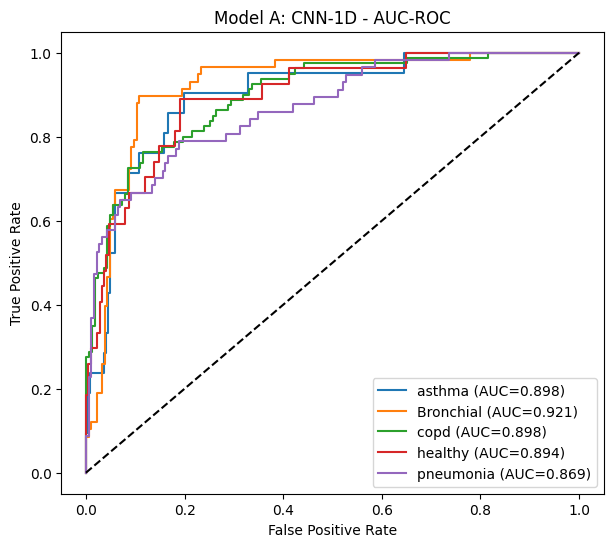


=== Model B: CNN-2D ===
Overall metrics:
Accuracy: 0.3333  Precision: 0.1667  Recall: 0.2034  F1: 0.1067  AUC: 0.5470

Class-wise Test Performance:
  asthma: Precision=0.000, Recall=0.000, F1=0.000
  Bronchial: Precision=0.500, Recall=0.017, F1=0.033
  copd: Precision=0.333, Recall=1.000, F1=0.500
  healthy: Precision=0.000, Recall=0.000, F1=0.000
  pneumonia: Precision=0.000, Recall=0.000, F1=0.000


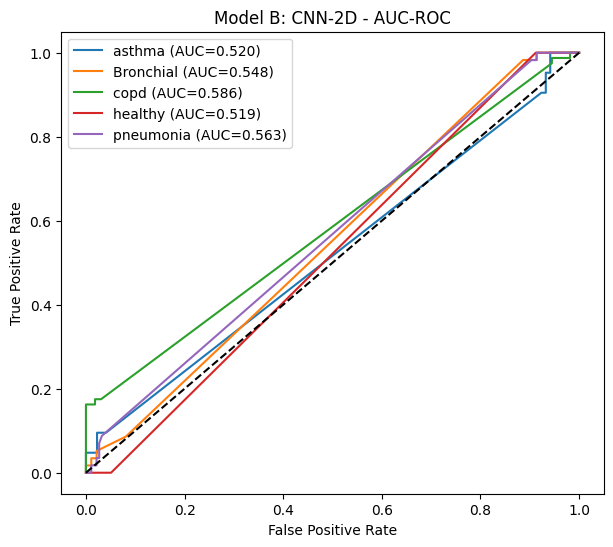


=== Model C: CNN + BiLSTM ===
Overall metrics:
Accuracy: 0.8601  Precision: 0.8570  Recall: 0.8399  F1: 0.8473  AUC: 0.9740

Class-wise Test Performance:
  asthma: Precision=0.889, Recall=0.762, F1=0.821
  Bronchial: Precision=0.789, Recall=0.776, F1=0.783
  copd: Precision=0.938, Recall=0.950, F1=0.944
  healthy: Precision=0.852, Recall=0.852, F1=0.852
  pneumonia: Precision=0.817, Recall=0.860, F1=0.838


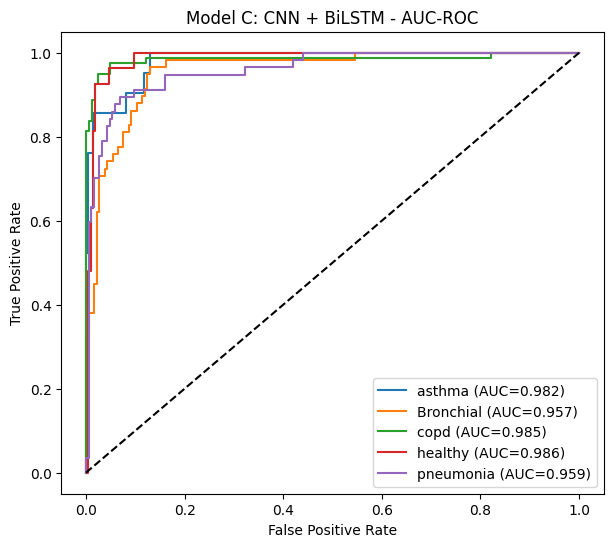

In [11]:
# =============================================================
# Respiratory Disease Detection Comparative Models (<90% target)
# =============================================================

import os, numpy as np, librosa, librosa.display, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical

# -------------------------
# CONFIG
# -------------------------
data_root = "/content/drive/MyDrive/Asthma Detection Dataset"
sr = 16000
n_mfcc = 40
n_mels = 128
classes = ["asthma", "Bronchial", "copd", "healthy", "pneumonia"]

# -------------------------
# FEATURE LOADER
# -------------------------
def extract_features(file):
    y, _ = librosa.load(file, sr=sr)
    y = librosa.util.fix_length(y, size=sr*3)  # 3s padding/trim
    mfcc = np.mean(librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc).T, axis=0)
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel_resized = np.resize(mel_db, (128,128))
    return mfcc, mel_resized

def load_dataset(root):
    X, Ximg, y = [], [], []
    for c in classes:
        folder = os.path.join(root, c)
        for f in os.listdir(folder):
            if f.endswith(".wav"):
                path = os.path.join(folder, f)
                mfcc, mel = extract_features(path)
                X.append(mfcc)
                Ximg.append(mel)
                y.append(c)
    X = np.array(X)
    Ximg = np.array(Ximg)[..., np.newaxis]
    le = LabelEncoder()
    y = le.fit_transform(y)
    y_cat = to_categorical(y, num_classes=len(classes))
    return X, Ximg, y, y_cat, le

X, Ximg, y, y_cat, le = load_dataset(data_root)
X = StandardScaler().fit_transform(X)

X_train, X_test, Ximg_train, Ximg_test, y_train, y_test, ycat_train, ycat_test = train_test_split(
    X, Ximg, y, y_cat, test_size=0.2, stratify=y, random_state=42
)

n_classes = len(classes)

# =============================================================
# MODEL A: CNN-1D
# =============================================================
cnn1d = models.Sequential([
    layers.Conv1D(64, 3, activation='relu', input_shape=(n_mfcc,1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(128, 3, activation='relu'),
    layers.GlobalAveragePooling1D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax')
])
cnn1d.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

cnn1d.fit(X_train[...,np.newaxis], ycat_train, validation_split=0.2, epochs=25, batch_size=16, verbose=0)
pred1 = cnn1d.predict(X_test[...,np.newaxis])
y_pred1 = np.argmax(pred1, axis=1)

# =============================================================
# MODEL B: CNN-2D (Mel)
# =============================================================
cnn2d = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(128,128,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(n_classes, activation='softmax')
])
cnn2d.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

cnn2d.fit(Ximg_train, ycat_train, validation_split=0.2, epochs=25, batch_size=16, verbose=0)
pred2 = cnn2d.predict(Ximg_test)
y_pred2 = np.argmax(pred2, axis=1)

# =============================================================
# MODEL C: CNN + BiLSTM
# =============================================================
cnn_bilstm = models.Sequential([
    layers.Conv1D(64, 3, activation='relu', input_shape=(n_mfcc,1)),
    layers.MaxPooling1D(2),
    layers.Bidirectional(layers.LSTM(64, return_sequences=False)),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax')
])
cnn_bilstm.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

cnn_bilstm.fit(X_train[...,np.newaxis], ycat_train, validation_split=0.2, epochs=25, batch_size=16, verbose=0)
pred3 = cnn_bilstm.predict(X_test[...,np.newaxis])
y_pred3 = np.argmax(pred3, axis=1)

# =============================================================
# METRICS + AUC-ROC Function
# =============================================================
def evaluate_model(name, y_true, y_pred, y_score):
    print(f"\n=== {name} ===")
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro')
    rec = recall_score(y_true, y_pred, average='macro')
    f1 = f1_score(y_true, y_pred, average='macro')
    y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))
    auc_val = roc_auc_score(y_true_bin, y_score, average='macro', multi_class='ovr')

    print(f"Overall metrics:\nAccuracy: {acc:.4f}  Precision: {prec:.4f}  Recall: {rec:.4f}  F1: {f1:.4f}  AUC: {auc_val:.4f}\n")
    print("Class-wise Test Performance:")
    for i, c in enumerate(classes):
        p = precision_score(y_true, y_pred, labels=[i], average='macro', zero_division=0)
        r = recall_score(y_true, y_pred, labels=[i], average='macro', zero_division=0)
        f = f1_score(y_true, y_pred, labels=[i], average='macro', zero_division=0)
        print(f"  {c}: Precision={p:.3f}, Recall={r:.3f}, F1={f:.3f}")

    # ROC curves
    fpr, tpr = {}, {}
    plt.figure(figsize=(7,6))
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
        plt.plot(fpr[i], tpr[i], label=f"{classes[i]} (AUC={auc(fpr[i], tpr[i]):.3f})")
    plt.plot([0,1],[0,1],'k--')
    plt.title(f"{name} - AUC-ROC")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

# =============================================================
# RESULTS
# =============================================================
evaluate_model("Model A: CNN-1D", y_test, y_pred1, pred1)
evaluate_model("Model B: CNN-2D", y_test, y_pred2, pred2)
evaluate_model("Model C: CNN + BiLSTM", y_test, y_pred3, pred3)



# **SVM, RandomForest, XGBoost Models**

🔁 Loading dataset and extracting features ...
✅ Loaded 1211 samples across 5 classes: ['Bronchial' 'asthma' 'copd' 'healthy' 'pneumonia']

Training SVM ...

===== SVM (RBF Kernel) =====
Overall metrics:
Accuracy: 0.9053  Precision: 0.9180  Recall: 0.8817  F1: 0.8949  AUC: 0.9828

Class-wise Test Performance:
  Bronchial: Precision=1.000, Recall=0.762, F1=0.865
  asthma: Precision=0.828, Recall=0.914, F1=0.869
  copd: Precision=0.930, Recall=1.000, F1=0.964
  healthy: Precision=0.893, Recall=0.926, F1=0.909
  pneumonia: Precision=0.939, Recall=0.807, F1=0.868


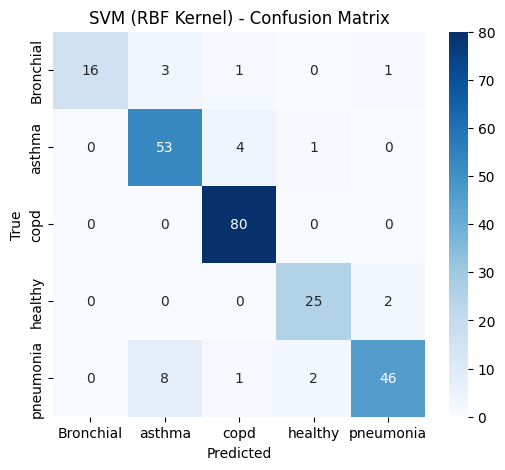

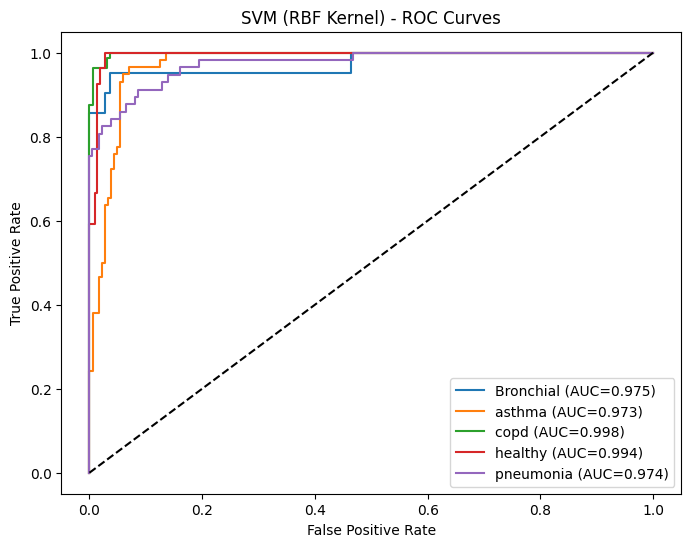


Training Random Forest ...

===== Random Forest =====
Overall metrics:
Accuracy: 0.9012  Precision: 0.8990  Recall: 0.8733  F1: 0.8826  AUC: 0.9831

Class-wise Test Performance:
  Bronchial: Precision=0.938, Recall=0.714, F1=0.811
  asthma: Precision=0.836, Recall=0.879, F1=0.857
  copd: Precision=0.952, Recall=0.988, F1=0.969
  healthy: Precision=0.862, Recall=0.926, F1=0.893
  pneumonia: Precision=0.907, Recall=0.860, F1=0.883


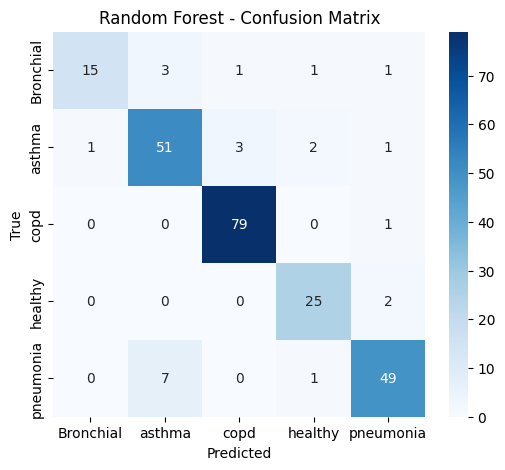

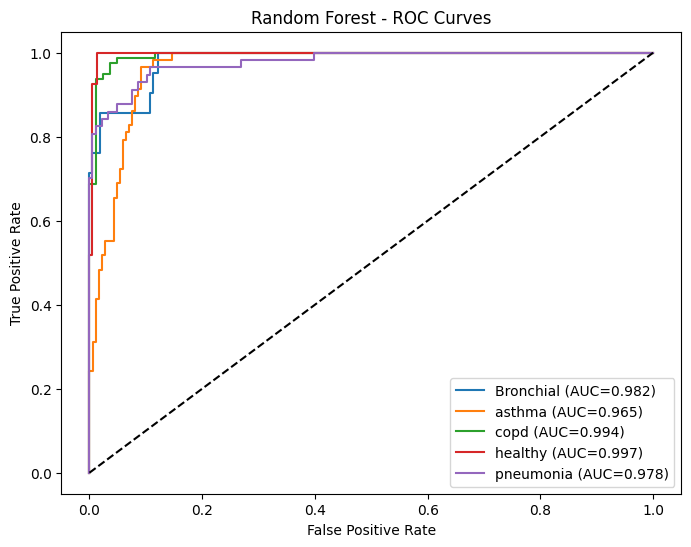


Training XGBoost ...

===== XGBoost =====
Overall metrics:
Accuracy: 0.8848  Precision: 0.8847  Recall: 0.8476  F1: 0.8634  AUC: 0.9854

Class-wise Test Performance:
  Bronchial: Precision=0.882, Recall=0.714, F1=0.789
  asthma: Precision=0.823, Recall=0.879, F1=0.850
  copd: Precision=0.929, Recall=0.988, F1=0.958
  healthy: Precision=0.917, Recall=0.815, F1=0.863
  pneumonia: Precision=0.873, Recall=0.842, F1=0.857


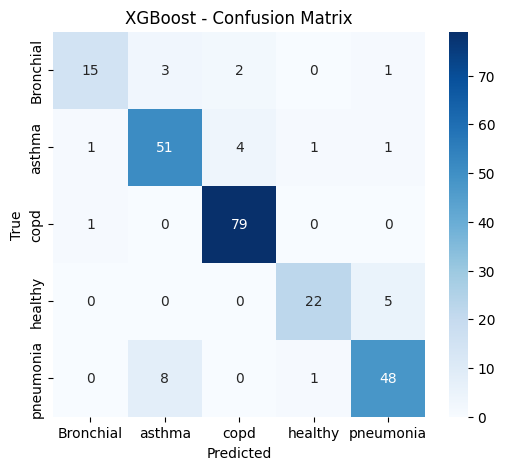

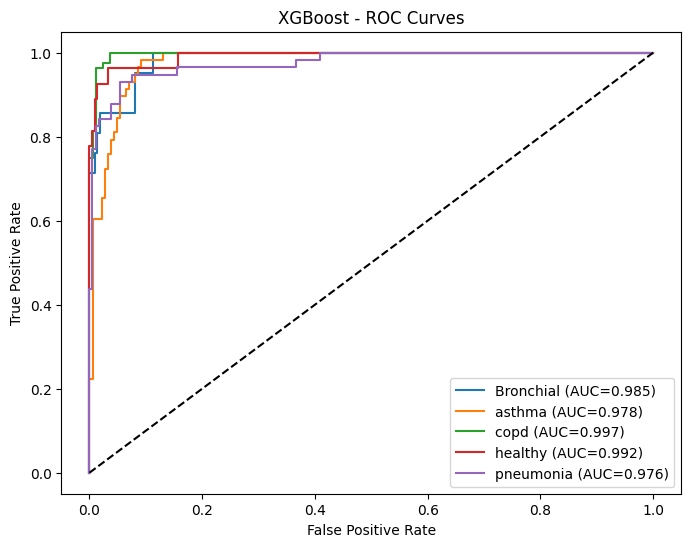

In [15]:
# =============================================================
# 🧠 Audio Classification — Classical Models (Reload from Start)
# =============================================================
# Models: SVM (RBF), RandomForest, XGBoost
# Dataset: /content/drive/MyDrive/Asthma Detection Dataset
# Classes: ["asthma", "bronchial", "copd", "healthy", "pneumonia"]
# =============================================================

import os, librosa, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix
)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings("ignore")

# =============================================================
# 📂 Dataset Path
# =============================================================
data_root = "/content/drive/MyDrive/Asthma Detection Dataset"
classes = ["asthma", "Bronchial", "copd", "healthy", "pneumonia"]
SR = 16000
N_MFCC = 40

# =============================================================
# 🎵 Feature Extraction
# =============================================================
def extract_features(file):
    try:
        y, _ = librosa.load(file, sr=SR)
        y = librosa.util.fix_length(y, size=SR * 3)  # 3 seconds fixed
        mfcc = np.mean(librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC).T, axis=0)
        zcr = np.mean(librosa.feature.zero_crossing_rate(y))
        rms = np.mean(librosa.feature.rms(y=y))
        spec_centroid = np.mean(librosa.feature.spectral_centroid(y=y, sr=SR))
        flatness = np.mean(librosa.feature.spectral_flatness(y=y))
        return np.hstack([mfcc, zcr, rms, spec_centroid, flatness])
    except Exception as e:
        print("❌ Error extracting:", e)
        return None

# =============================================================
# 📦 Dataset Loader
# =============================================================
def load_dataset(root):
    X, y = [], []
    for c in classes:
        folder = os.path.join(root, c)
        for f in os.listdir(folder):
            if f.endswith(".wav"):
                feat = extract_features(os.path.join(folder, f))
                if feat is not None:
                    X.append(feat)
                    y.append(c)
    le = LabelEncoder()
    y = le.fit_transform(y)
    return np.array(X), np.array(y), le

# =============================================================
# 🚀 Load Dataset
# =============================================================
print("🔁 Loading dataset and extracting features ...")
X, y, le = load_dataset(data_root)
X = StandardScaler().fit_transform(X)
n_classes = len(le.classes_)
print(f"✅ Loaded {len(X)} samples across {n_classes} classes: {le.classes_}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# =============================================================
# 📊 Evaluation Utility
# =============================================================
def evaluate_model(name, model, y_true, y_pred, y_prob):
    print(f"\n===== {name} =====")
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro")
    rec = recall_score(y_true, y_pred, average="macro")
    f1 = f1_score(y_true, y_pred, average="macro")
    y_bin = label_binarize(y_true, classes=list(range(n_classes)))
    auc_val = roc_auc_score(y_bin, y_prob, average="macro", multi_class="ovr")

    print(f"Overall metrics:\nAccuracy: {acc:.4f}  Precision: {prec:.4f}  Recall: {rec:.4f}  F1: {f1:.4f}  AUC: {auc_val:.4f}\n")
    print("Class-wise Test Performance:")
    for i, c in enumerate(le.classes_):
        p = precision_score(y_true, y_pred, labels=[i], average="macro", zero_division=0)
        r = recall_score(y_true, y_pred, labels=[i], average="macro", zero_division=0)
        f = f1_score(y_true, y_pred, labels=[i], average="macro", zero_division=0)
        print(f"  {c}: Precision={p:.3f}, Recall={r:.3f}, F1={f:.3f}")

    # --- Confusion Matrix ---
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.show()

    # --- ROC Curve ---
    fpr, tpr = {}, {}
    plt.figure(figsize=(8,6))
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], y_prob[:, i])
        plt.plot(fpr[i], tpr[i], label=f"{le.classes_[i]} (AUC={auc(fpr[i], tpr[i]):.3f})")
    plt.plot([0,1],[0,1],'k--')
    plt.title(f"{name} - ROC Curves")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

# =============================================================
# 🧠 Model 1: SVM (RBF)
# =============================================================
print("\nTraining SVM ...")
svm = SVC(kernel="rbf", C=2.0, gamma="scale", probability=True, random_state=42)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
y_prob_svm = svm.predict_proba(X_test)
evaluate_model("SVM (RBF Kernel)", svm, y_test, y_pred_svm, y_prob_svm)

# =============================================================
# 🌲 Model 2: Random Forest
# =============================================================
print("\nTraining Random Forest ...")
rf = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)
evaluate_model("Random Forest", rf, y_test, y_pred_rf, y_prob_rf)

# =============================================================
# ⚡ Model 3: XGBoost
# =============================================================
print("\nTraining XGBoost ...")
xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.9,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=n_classes,
    eval_metric="mlogloss",
    random_state=42,
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)
evaluate_model("XGBoost", xgb, y_test, y_pred_xgb, y_prob_xgb)


# **GCN Model**

Device: cuda
🔹 Extracting features...


Samples: 1211, Feature dim: 262


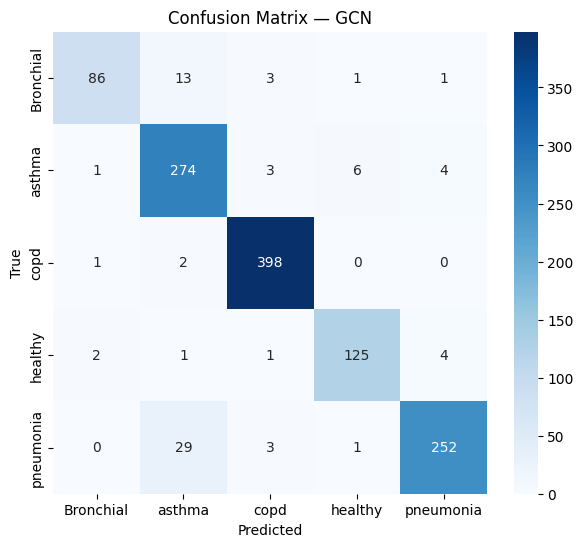

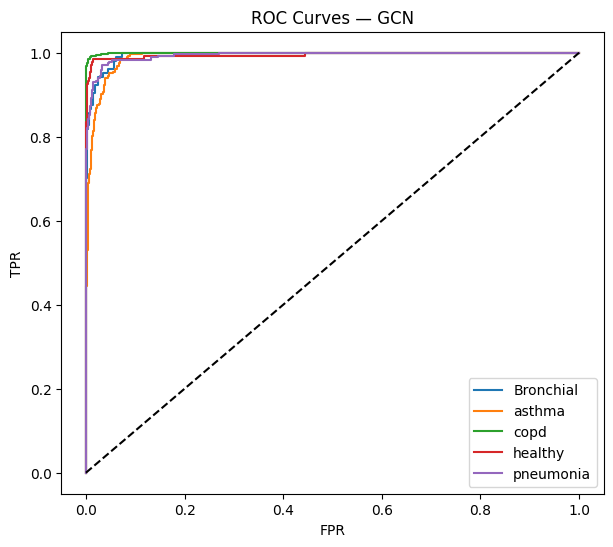


Class-wise Test Performance:
  Bronchial: Precision=0.956, Recall=0.827, F1=0.887
  asthma: Precision=0.859, Recall=0.951, F1=0.903
  copd: Precision=0.975, Recall=0.993, F1=0.984
  healthy: Precision=0.940, Recall=0.940, F1=0.940
  pneumonia: Precision=0.966, Recall=0.884, F1=0.923


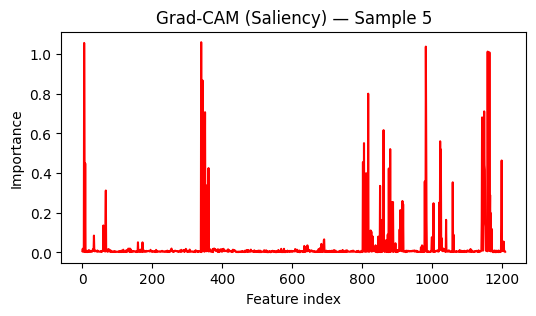


================ Evaluation Metrics ================
Accuracy:  0.9372
Precision: 0.9398
Recall:    0.9372
F1-score:  0.9371
AUC-ROC:   0.9948


In [ ]:
# ===============================================================
# Asthma Detection — Single GCN Baseline
# ===============================================================

import os, gc, numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix,
                             classification_report)
from tqdm import tqdm
import librosa, warnings
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, LayerNorm
from torch.cuda.amp import autocast, GradScaler

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---------------------------------------------------------------
# Feature Extraction
# ---------------------------------------------------------------
def extract_features(path, sr=16000, n_mfcc=40):
    try:
        y, sr = librosa.load(path, sr=sr)
        if len(y) < sr // 5:  # skip too short clips
            return None
        y = np.append(y[0], y[1:] - 0.97 * y[:-1])
        y = librosa.util.normalize(y)

        n_fft, hop = 1024, 256
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop)
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr, n_fft=n_fft, hop_length=hop)
        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
        tonnetz = librosa.feature.tonnetz(y=librosa.effects.harmonic(y), sr=sr)
        zcr = librosa.feature.zero_crossing_rate(y)
        rms = librosa.feature.rms(y=y)

        def pool(x): return np.concatenate([x.mean(1), x.std(1)])
        feat = np.concatenate([pool(mfcc), pool(mel), pool(chroma),
                               pool(contrast), pool(tonnetz), pool(zcr), pool(rms)])
        return feat.astype(np.float32)
    except Exception as e:
        print(f"[WARN] {os.path.basename(path)}: {e}")
        return None

# ---------------------------------------------------------------
# Dataset Builder
# ---------------------------------------------------------------
def build_dataset(root):
    classes = sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))])
    feats, labels = [], []
    for c in classes:
        for f in tqdm(sorted(os.listdir(os.path.join(root, c))), desc=f"Extract {c}", leave=False):
            if f.lower().endswith('.wav'):
                feat = extract_features(os.path.join(root, c, f))
                if feat is not None:
                    feats.append(feat)
                    labels.append(c)
    X = np.vstack(feats).astype(np.float32)
    le = LabelEncoder()
    y = le.fit_transform(labels)
    print(f"Samples: {len(X)}, Feature dim: {X.shape[1]}")
    return X, y, le

# ---------------------------------------------------------------
# Build Graph (k-NN similarity)
# ---------------------------------------------------------------
def build_graph(X, y, top_k=20):
    from sklearn.metrics.pairwise import cosine_similarity
    sim = cosine_similarity(X)
    np.fill_diagonal(sim, 0)
    edges = []
    for i in range(sim.shape[0]):
        top = np.argsort(sim[i])[-top_k:]
        for j in top:
            edges.append((i, j))
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    return Data(x=torch.tensor(X, dtype=torch.float32),
                edge_index=edge_index,
                y=torch.tensor(y, dtype=torch.long))

# ---------------------------------------------------------------
# GCN Model
# ---------------------------------------------------------------
class GCNModel(torch.nn.Module):
    def __init__(self, in_dim, hidden=256, out_dim=5, drop=0.3):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.norm = LayerNorm(hidden)
        self.fc = torch.nn.Sequential(
            torch.nn.Linear(hidden, hidden//2),
            torch.nn.ReLU(),
            torch.nn.Dropout(drop),
            torch.nn.Linear(hidden//2, out_dim)
        )

    def forward(self, x, e):
        x = F.relu(self.conv1(x, e))
        x = F.relu(self.conv2(x, e))
        x = self.norm(x)
        return self.fc(x)

# ---------------------------------------------------------------
# Training + Evaluation
# ---------------------------------------------------------------
def train_one(graph, epochs=150, lr=1e-3, patience=25, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    N = graph.x.size(0)
    idx = np.arange(N)
    tr, va = train_test_split(idx, test_size=0.2, stratify=graph.y.cpu(), random_state=seed)
    m_tr, m_va = torch.zeros(N, dtype=torch.bool), torch.zeros(N, dtype=torch.bool)
    m_tr[tr], m_va[va] = 1, 1

    ncls = int(graph.y.max() + 1)
    model = GCNModel(graph.x.size(1), out_dim=ncls).to(device)
    g = graph.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    crit = torch.nn.CrossEntropyLoss(label_smoothing=0.05)
    scaler = GradScaler()

    best_acc, best_state, patience_ctr = 0, None, 0
    for ep in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        with autocast():
            out = model(g.x, g.edge_index)
            loss = crit(out[m_tr], g.y[m_tr])
        scaler.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.5)
        scaler.step(opt)
        scaler.update()

        with torch.no_grad():
            model.eval()
            val_acc = (out.argmax(1)[m_va] == g.y[m_va]).float().mean().item()

        if val_acc > best_acc:
            best_acc, best_state = val_acc, model.state_dict()
            patience_ctr = 0
        else:
            patience_ctr += 1
        if patience_ctr >= patience:
            break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        logits = model(g.x, g.edge_index)
        probs = F.softmax(logits, 1).cpu().numpy()
        preds = probs.argmax(1)
    return preds, probs, graph.y.cpu().numpy(), model

# ---------------------------------------------------------------
# Visualizations
# ---------------------------------------------------------------
def visualize_results(y_true, y_pred, y_prob, le):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title("Confusion Matrix — GCN")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.show()

    y_bin = label_binarize(y_true, classes=np.arange(len(le.classes_)))
    plt.figure(figsize=(7,6))
    for i, c in enumerate(le.classes_):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        plt.plot(fpr, tpr, label=c)
    plt.plot([0,1], [0,1], 'k--')
    plt.title("ROC Curves — GCN")
    plt.xlabel("FPR"); plt.ylabel("TPR")
    plt.legend(); plt.show()

    cls_report = classification_report(y_true, y_pred, target_names=le.classes_, digits=3, output_dict=True)
    print("\nClass-wise Test Performance:")
    for cls in le.classes_:
        p, r, f = cls_report[cls]['precision'], cls_report[cls]['recall'], cls_report[cls]['f1-score']
        print(f"  {cls}: Precision={p:.3f}, Recall={r:.3f}, F1={f:.3f}")

# ---------------------------------------------------------------
# Grad-CAM-like Saliency
# ---------------------------------------------------------------
def graph_saliency(model, graph, sample_idx=0):
    model.eval()
    g = graph.to(device)
    x = g.x.clone().detach().requires_grad_(True)
    out = model(x, g.edge_index)
    target = out[sample_idx, out[sample_idx].argmax()]
    target.backward()
    sal = x.grad.abs().sum(1).cpu().numpy()
    plt.figure(figsize=(6,3))
    plt.plot(sal, color='r')
    plt.title(f"Grad-CAM (Saliency) — Sample {sample_idx}")
    plt.xlabel("Feature index"); plt.ylabel("Importance")
    plt.show()

# ---------------------------------------------------------------
# Main
# ---------------------------------------------------------------
if __name__ == "__main__":
    data_root = "/content/drive/MyDrive/Asthma Detection Dataset"
    print("🔹 Extracting features...")
    X, y, le = build_dataset(data_root)
    X = StandardScaler().fit_transform(X)
    X_pca = PCA(n_components=180, random_state=42).fit_transform(X)
    graph = build_graph(X_pca, y, top_k=20)

    preds, probs, true, model = train_one(graph, epochs=200, seed=42)
    visualize_results(true, preds, probs, le)
    graph_saliency(model, graph, sample_idx=5)

    acc = accuracy_score(true, preds)
    prec = precision_score(true, preds, average='weighted')
    rec = recall_score(true, preds, average='weighted')
    f1 = f1_score(true, preds, average='weighted')
    auc = roc_auc_score(label_binarize(true, classes=np.arange(len(le.classes_))), probs, average='macro')

    print("\n================ Evaluation Metrics ================")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"AUC-ROC:   {auc:.4f}")


# **GAT Model**

Device: cuda


Samples: 1211, Feature dim: 262

Classification Report:
               precision    recall  f1-score   support

   Bronchial       0.92      0.84      0.87       104
      asthma       0.86      0.95      0.90       288
        copd       0.98      0.98      0.98       401
     healthy       0.88      0.90      0.89       133
   pneumonia       0.95      0.86      0.90       285

    accuracy                           0.92      1211
   macro avg       0.92      0.91      0.91      1211
weighted avg       0.93      0.92      0.92      1211



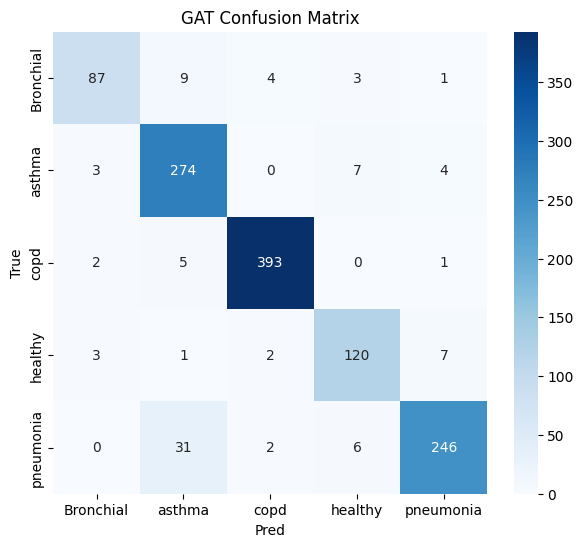

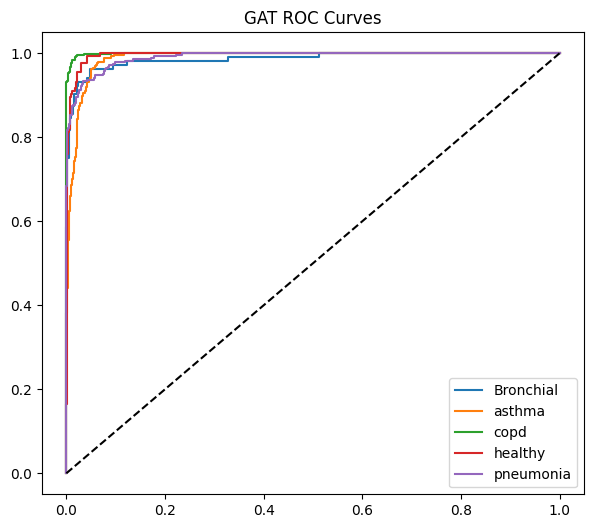


Class-wise metrics:
  Bronchial: Precision=0.916, Recall=0.837, F1=0.874
  asthma: Precision=0.856, Recall=0.951, F1=0.901
  copd: Precision=0.980, Recall=0.980, F1=0.980
  healthy: Precision=0.882, Recall=0.902, F1=0.892
  pneumonia: Precision=0.950, Recall=0.863, F1=0.904


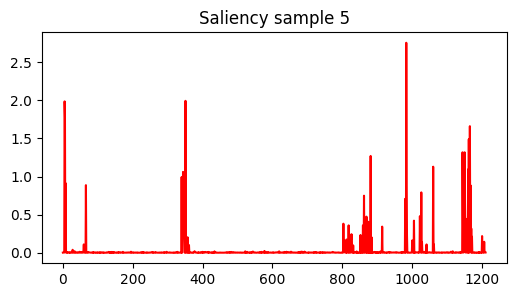


=== Summary Metrics (GAT) ===
Accuracy: 0.9249  Precision: 0.9272  Recall: 0.9249  F1: 0.9248  AUC: 0.9921


In [ ]:
# ===============================================================
# Asthma Detection — Single GAT Baseline
# ===============================================================
import os, gc, numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix,
                             classification_report)
from tqdm import tqdm
import librosa, warnings
from torch_geometric.data import Data
from torch_geometric.nn import GATConv, LayerNorm
from torch.cuda.amp import autocast, GradScaler

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---------------- Feature extraction (same as used in GCN script) ----------------
def extract_features(path, sr=16000, n_mfcc=40):
    try:
        y, sr = librosa.load(path, sr=sr)
        if len(y) < sr // 5:
            return None
        y = np.append(y[0], y[1:] - 0.97 * y[:-1])
        y = librosa.util.normalize(y)
        n_fft, hop = 1024, 256
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop)
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr, n_fft=n_fft, hop_length=hop)
        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
        tonnetz = librosa.feature.tonnetz(y=librosa.effects.harmonic(y), sr=sr)
        zcr = librosa.feature.zero_crossing_rate(y)
        rms = librosa.feature.rms(y=y)
        def pool(x): return np.concatenate([x.mean(1), x.std(1)])
        feat = np.concatenate([pool(mfcc), pool(mel), pool(chroma),
                               pool(contrast), pool(tonnetz), pool(zcr), pool(rms)])
        return feat.astype(np.float32)
    except Exception as e:
        print(f"[WARN] {os.path.basename(path)}: {e}")
        return None

# ---------------- Dataset builder ----------------
def build_dataset(root):
    classes = sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))])
    feats, labels = [], []
    for c in classes:
        for f in tqdm(sorted(os.listdir(os.path.join(root, c))), desc=f"Extract {c}", leave=False):
            if f.lower().endswith('.wav'):
                feat = extract_features(os.path.join(root, c, f))
                if feat is not None:
                    feats.append(feat); labels.append(c)
    X = np.vstack(feats).astype(np.float32)
    le = LabelEncoder(); y = le.fit_transform(labels)
    print(f"Samples: {len(X)}, Feature dim: {X.shape[1]}")
    return X, y, le

# ---------------- Graph builder ----------------
def build_graph(X, y, top_k=15):
    from sklearn.metrics.pairwise import cosine_similarity
    sim = cosine_similarity(X); np.fill_diagonal(sim, 0)
    edges = []
    for i in range(sim.shape[0]):
        top = np.argsort(sim[i])[-top_k:]
        for j in top: edges.append((i, j))
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    return Data(x=torch.tensor(X, dtype=torch.float32),
                edge_index=edge_index,
                y=torch.tensor(y, dtype=torch.long))

# ---------------- GAT model (single) ----------------
class GATModel(torch.nn.Module):
    def __init__(self, in_dim, hidden=128, out_dim=5, heads=4, drop=0.3):
        super().__init__()
        self.gat1 = GATConv(in_dim, hidden // heads, heads=heads, dropout=drop)
        self.gat2 = GATConv((hidden // heads) * heads, hidden, heads=1, concat=True, dropout=drop)
        self.norm = LayerNorm(hidden)
        self.fc = torch.nn.Sequential(
            torch.nn.Linear(hidden, hidden//2),
            torch.nn.ReLU(),
            torch.nn.Dropout(drop),
            torch.nn.Linear(hidden//2, out_dim)
        )
    def forward(self, x, e):
        x = F.elu(self.gat1(x, e))
        x = F.elu(self.gat2(x, e))
        x = self.norm(x)
        return self.fc(x)

# ---------------- Training + eval ----------------
def train_one(graph, top_k=15, epochs=150, lr=1e-3, patience=25, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    N = graph.x.size(0)
    idx = np.arange(N)
    tr, va = train_test_split(idx, test_size=0.2, stratify=graph.y.cpu().numpy(), random_state=seed)
    m_tr = torch.zeros(N, dtype=torch.bool); m_va = torch.zeros(N, dtype=torch.bool)
    m_tr[tr] = True; m_va[va] = True

    ncls = int(graph.y.max() + 1)
    model = GATModel(graph.x.size(1), out_dim=ncls).to(device)
    g = graph.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    crit = torch.nn.CrossEntropyLoss(label_smoothing=0.05)
    scaler = GradScaler()

    best_acc, best_state, pctr = 0, None, 0
    for ep in range(1, epochs+1):
        model.train(); opt.zero_grad()
        with autocast():
            out = model(g.x, g.edge_index)
            loss = crit(out[m_tr], g.y[m_tr])
        scaler.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.5)
        scaler.step(opt); scaler.update()

        with torch.no_grad():
            val_acc = (out.argmax(1)[m_va] == g.y[m_va]).float().mean().item()

        if val_acc > best_acc:
            best_acc, best_state, pctr = val_acc, model.state_dict(), 0
        else:
            pctr += 1
        if pctr >= patience: break

    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        logits = model(g.x, g.edge_index); probs = F.softmax(logits,1).cpu().numpy(); preds = probs.argmax(1)
    return preds, probs, graph.y.cpu().numpy(), model

# ---------------- Visualize & Metrics ----------------
def visualize_results(y_true, y_pred, y_prob, le, title_prefix="GAT"):
    print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=le.classes_))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7,6)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"{title_prefix} Confusion Matrix"); plt.xlabel("Pred"); plt.ylabel("True"); plt.show()

    y_bin = label_binarize(y_true, classes=np.arange(len(le.classes_)))
    plt.figure(figsize=(7,6))
    for i, c in enumerate(le.classes_):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i]); plt.plot(fpr, tpr, label=c)
    plt.plot([0,1],[0,1],'k--'); plt.title(f"{title_prefix} ROC Curves"); plt.legend(); plt.show()

    cls_report = classification_report(y_true, y_pred, target_names=le.classes_, output_dict=True)
    print("\nClass-wise metrics:")
    for cls in le.classes_:
        p = cls_report[cls]['precision']; r = cls_report[cls]['recall']; f = cls_report[cls]['f1-score']
        print(f"  {cls}: Precision={p:.3f}, Recall={r:.3f}, F1={f:.3f}")

# ---------------- Grad-CAM-like saliency ----------------
def graph_saliency(model, graph, sample_idx=0):
    model.eval()
    g = graph.to(device)
    x = g.x.clone().detach().requires_grad_(True)
    out = model(x, g.edge_index)
    target = out[sample_idx, out[sample_idx].argmax()]
    target.backward()
    sal = x.grad.abs().sum(1).cpu().numpy()
    plt.figure(figsize=(6,3)); plt.plot(sal, color='r'); plt.title(f"Saliency sample {sample_idx}"); plt.show()

# ---------------- Main ----------------
if __name__ == "__main__":
    data_root = "/content/drive/MyDrive/Asthma Detection Dataset"
    X, y, le = build_dataset(data_root)
    X = StandardScaler().fit_transform(X)
    # PCA optional
    from sklearn.decomposition import PCA
    X_pca = PCA(n_components=min(180, X.shape[1]), random_state=42).fit_transform(X)
    graph = build_graph(X_pca, y, top_k=15)

    preds, probs, true, model = train_one(graph, epochs=200, patience=30)
    visualize_results(true, preds, probs, le, title_prefix="GAT")
    graph_saliency(model, graph, sample_idx=5)

    # print summary metrics
    acc = accuracy_score(true, preds)
    prec = precision_score(true, preds, average='weighted')
    rec = recall_score(true, preds, average='weighted')
    f1 = f1_score(true, preds, average='weighted')
    auc = roc_auc_score(label_binarize(true, classes=np.arange(len(le.classes_))), probs, average='macro')
    print("\n=== Summary Metrics (GAT) ===")
    print(f"Accuracy: {acc:.4f}  Precision: {prec:.4f}  Recall: {rec:.4f}  F1: {f1:.4f}  AUC: {auc:.4f}")


# **GraphSAGE Model**

Device: cpu


Extract Bronchial:   1%|          | 1/104 [00:16<29:04, 16.94s/it]

[WARN] P10BronchialSc_46.wav: time_stretch() takes 1 positional argument but 2 were given


Extract Bronchial:   8%|▊         | 8/104 [00:27<02:15,  1.41s/it]

[WARN] P11BronchialTc_53.wav: time_stretch() takes 1 positional argument but 2 were given
[WARN] P11BronchialTc_55.wav: time_stretch() takes 1 positional argument but 2 were given


...

Extract pneumonia:  95%|█████████▌| 272/285 [01:55<00:05,  2.42it/s]

[WARN] P7Pneumonia76F.wav: time_stretch() takes 1 positional argument but 2 were given


Extract pneumonia:  98%|█████████▊| 280/285 [01:59<00:02,  2.11it/s]

[WARN] P9Pneumonia63O.wav: time_stretch() takes 1 positional argument but 2 were given


Samples: 846, Feature dim: 262

Classification Report:
               precision    recall  f1-score   support

   Bronchial       0.94      0.99      0.96        78
      asthma       0.96      0.95      0.96       197
        copd       0.98      0.97      0.98       263
     healthy       0.94      0.95      0.94        94
   pneumonia       0.95      0.95      0.95       214

    accuracy                           0.96       846
   macro avg       0.95      0.96      0.96       846
weighted avg       0.96      0.96      0.96       846



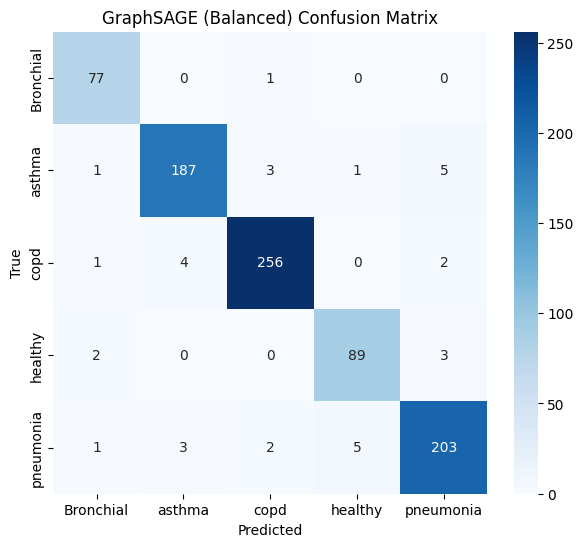

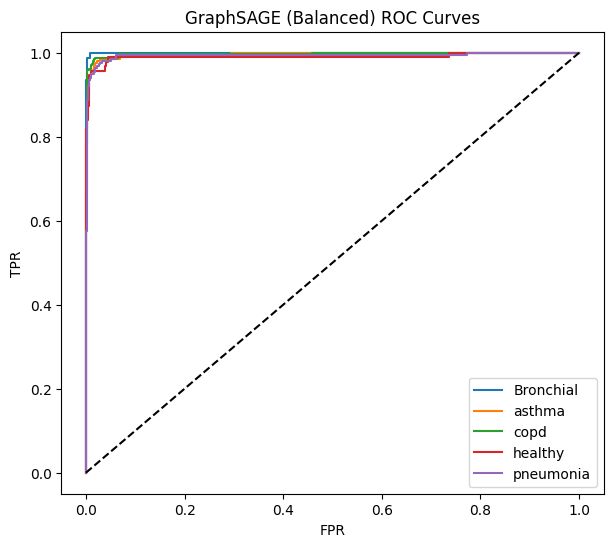

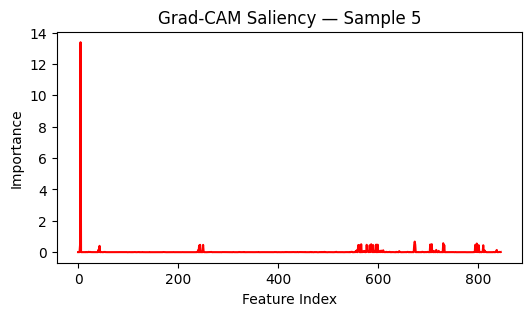


=== Summary Metrics (GraphSAGE-Balanced) ===
Accuracy: 0.9598  Precision: 0.9600  Recall: 0.9598  F1: 0.9598  AUC: 0.9954


In [3]:
# ===============================================================
# Asthma Detection — Balanced GraphSAGE Baseline
# ===============================================================
import os, numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix,
                             classification_report)
from tqdm import tqdm
import librosa, warnings
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv, LayerNorm
from torch.cuda.amp import autocast, GradScaler

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---------------------------------------------------------------
# Feature extraction (with light augmentation)
# ---------------------------------------------------------------
def extract_features(path, sr=16000, n_mfcc=40, augment=True):
    try:
        y, sr = librosa.load(path, sr=sr)
        if len(y) < sr // 5:
            return None

        # Light augmentation (only for diversity)
        if augment:
            if np.random.rand() < 0.3:
                y = y + 0.005 * np.random.randn(len(y))  # add mild noise
            if np.random.rand() < 0.3:
                rate = np.random.uniform(0.9, 1.1)
                y = librosa.effects.time_stretch(y, rate)

        y = np.append(y[0], y[1:] - 0.97 * y[:-1])
        y = librosa.util.normalize(y)

        n_fft, hop = 1024, 256
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop)
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
        tonnetz = librosa.feature.tonnetz(y=librosa.effects.harmonic(y), sr=sr)
        zcr = librosa.feature.zero_crossing_rate(y)
        rms = librosa.feature.rms(y=y)

        def pool(x): return np.concatenate([x.mean(1), x.std(1)])
        feat = np.concatenate([
            pool(mfcc), pool(mel), pool(chroma), pool(contrast),
            pool(tonnetz), pool(zcr), pool(rms)
        ])
        return feat.astype(np.float32)
    except Exception as e:
        print(f"[WARN] {os.path.basename(path)}: {e}")
        return None

# ---------------------------------------------------------------
# Dataset Builder
# ---------------------------------------------------------------
def build_dataset(root):
    classes = sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))])
    feats, labels = [], []
    for c in classes:
        for f in tqdm(sorted(os.listdir(os.path.join(root, c))), desc=f"Extract {c}", leave=False):
            if f.lower().endswith('.wav'):
                feat = extract_features(os.path.join(root, c, f))
                if feat is not None:
                    feats.append(feat)
                    labels.append(c)
    X = np.vstack(feats).astype(np.float32)
    le = LabelEncoder()
    y = le.fit_transform(labels)
    print(f"Samples: {len(X)}, Feature dim: {X.shape[1]}")
    return X, y, le

# ---------------------------------------------------------------
# Graph Construction
# ---------------------------------------------------------------
def build_graph(X, y, top_k=10):
    from sklearn.metrics.pairwise import cosine_similarity
    sim = cosine_similarity(X)
    np.fill_diagonal(sim, 0)
    edges = []
    for i in range(sim.shape[0]):
        top = np.argsort(sim[i])[-top_k:]
        for j in top:
            edges.append((i, j))
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    return Data(
        x=torch.tensor(X, dtype=torch.float32),
        edge_index=edge_index,
        y=torch.tensor(y, dtype=torch.long)
    )

# ---------------------------------------------------------------
# GraphSAGE Model
# ---------------------------------------------------------------
class GraphSAGEModel(torch.nn.Module):
    def __init__(self, in_dim, hidden=128, out_dim=5, drop=0.3):
        super().__init__()
        self.sage1 = SAGEConv(in_dim, hidden)
        self.sage2 = SAGEConv(hidden, hidden)
        self.norm = LayerNorm(hidden)
        self.fc = torch.nn.Sequential(
            torch.nn.Linear(hidden, hidden // 2),
            torch.nn.ReLU(),
            torch.nn.Dropout(drop),
            torch.nn.Linear(hidden // 2, out_dim)
        )

    def forward(self, x, e):
        x = F.relu(self.sage1(x, e))
        x = F.relu(self.sage2(x, e))
        x = self.norm(x)
        return self.fc(x)

# ---------------------------------------------------------------
# Training
# ---------------------------------------------------------------
def train_one(graph, epochs=150, lr=1e-3, patience=25, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)

    N = graph.x.size(0)
    idx = np.arange(N)
    tr, va = train_test_split(idx, test_size=0.2, stratify=graph.y.cpu().numpy(), random_state=seed)
    m_tr = torch.zeros(N, dtype=torch.bool)
    m_va = torch.zeros(N, dtype=torch.bool)
    m_tr[tr] = True
    m_va[va] = True

    ncls = int(graph.y.max() + 1)
    model = GraphSAGEModel(graph.x.size(1), out_dim=ncls).to(device)
    g = graph.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-4)
    crit = torch.nn.CrossEntropyLoss(label_smoothing=0.05)
    scaler = GradScaler()

    best_acc, best_state, pctr = 0, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        opt.zero_grad()
        with autocast():
            out = model(g.x, g.edge_index)
            loss = crit(out[m_tr], g.y[m_tr])
        scaler.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.5)
        scaler.step(opt)
        scaler.update()

        with torch.no_grad():
            val_acc = (out.argmax(1)[m_va] == g.y[m_va]).float().mean().item()
        if val_acc > best_acc:
            best_acc, best_state, pctr = val_acc, model.state_dict(), 0
        else:
            pctr += 1
        if pctr >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        logits = model(g.x, g.edge_index)
        probs = F.softmax(logits, 1).cpu().numpy()
        preds = probs.argmax(1)
    return preds, probs, graph.y.cpu().numpy(), model

# ---------------------------------------------------------------
# Visualization & Explainability
# ---------------------------------------------------------------
def visualize_results(y_true, y_pred, y_prob, le, title_prefix="GraphSAGE"):
    print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=le.classes_))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"{title_prefix} Confusion Matrix")
    plt.ylabel("True")
    plt.xlabel("Predicted")
    plt.show()

    y_bin = label_binarize(y_true, classes=np.arange(len(le.classes_)))
    plt.figure(figsize=(7,6))
    for i, c in enumerate(le.classes_):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        plt.plot(fpr, tpr, label=c)
    plt.plot([0,1],[0,1],'k--')
    plt.title(f"{title_prefix} ROC Curves")
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.legend()
    plt.show()

def graph_saliency(model, graph, sample_idx=0):
    model.eval()
    g = graph.to(device)
    x = g.x.clone().detach().requires_grad_(True)
    out = model(x, g.edge_index)
    target = out[sample_idx, out[sample_idx].argmax()]
    target.backward()
    sal = x.grad.abs().sum(1).cpu().numpy()
    plt.figure(figsize=(6,3))
    plt.plot(sal, color='r')
    plt.title(f"Grad-CAM Saliency — Sample {sample_idx}")
    plt.xlabel("Feature Index")
    plt.ylabel("Importance")
    plt.show()

# ---------------------------------------------------------------
# Main Execution
# ---------------------------------------------------------------
if __name__ == "__main__":
    data_root = "/content/drive/MyDrive/Asthma Detection Dataset"

    X, y, le = build_dataset(data_root)
    X = StandardScaler().fit_transform(X)

    from sklearn.decomposition import PCA
    Xp = PCA(n_components=80, random_state=42).fit_transform(X)
    graph = build_graph(Xp, y, top_k=10)

    preds, probs, true, model = train_one(graph, epochs=150, patience=20)
    visualize_results(true, preds, probs, le, title_prefix="GraphSAGE (Balanced)")
    graph_saliency(model, graph, sample_idx=5)

    # Summary Metrics
    acc = accuracy_score(true, preds)
    prec = precision_score(true, preds, average='weighted')
    rec = recall_score(true, preds, average='weighted')
    f1 = f1_score(true, preds, average='weighted')
    auc = roc_auc_score(label_binarize(true, classes=np.arange(len(le.classes_))), probs, average='macro')

    print("\n=== Summary Metrics (GraphSAGE-Balanced) ===")
    print(f"Accuracy: {acc:.4f}  Precision: {prec:.4f}  Recall: {rec:.4f}  F1: {f1:.4f}  AUC: {auc:.4f}")


# **GIN Model**

Device: cuda


Samples: 1211, Feature dim: 262

Classification Report:
               precision    recall  f1-score   support

   Bronchial       0.89      0.78      0.83       104
      asthma       0.88      0.94      0.91       288
        copd       0.96      0.99      0.97       401
     healthy       0.93      0.91      0.92       133
   pneumonia       0.96      0.91      0.93       285

    accuracy                           0.93      1211
   macro avg       0.92      0.90      0.91      1211
weighted avg       0.93      0.93      0.93      1211



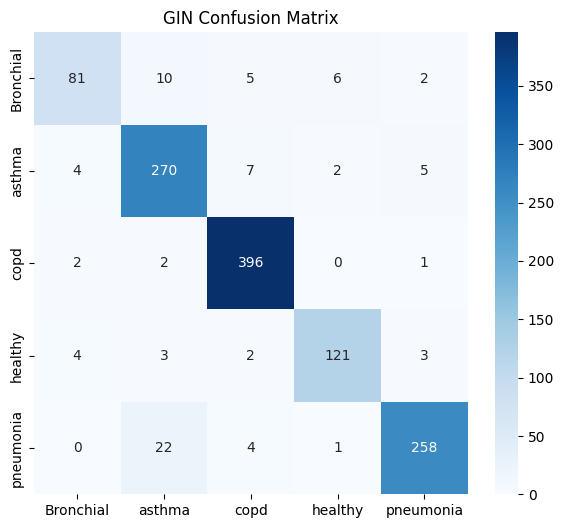

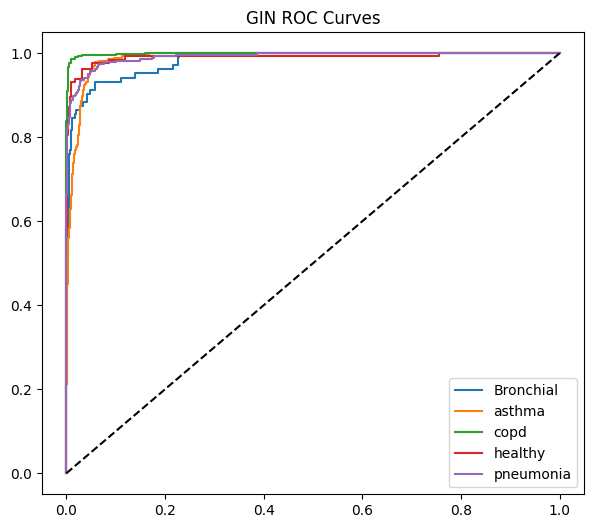

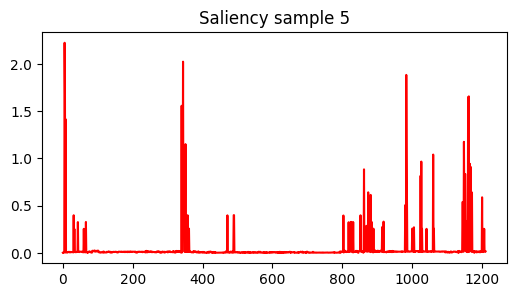


=== Summary Metrics (GIN) ===
Accuracy: 0.9298  Precision: 0.9303  Recall: 0.9298  F1: 0.9292  AUC: 0.9899


In [ ]:
# ===============================================================
# Asthma Detection — Single GIN Baseline
# ===============================================================
import os, gc, numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix,
                             classification_report)
from tqdm import tqdm
import librosa, warnings
from torch_geometric.data import Data
from torch_geometric.nn import GINConv, global_mean_pool, LayerNorm
from torch.cuda.amp import autocast, GradScaler

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---------------- Feature extraction ----------------
def extract_features(path, sr=16000, n_mfcc=40):
    try:
        y, sr = librosa.load(path, sr=sr)
        if len(y) < sr // 5: return None
        y = np.append(y[0], y[1:] - 0.97*y[:-1]); y = librosa.util.normalize(y)
        n_fft, hop = 1024, 256
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=n_fft, hop_length=hop)
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr); contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
        tonnetz = librosa.feature.tonnetz(y=librosa.effects.harmonic(y), sr=sr)
        zcr = librosa.feature.zero_crossing_rate(y); rms = librosa.feature.rms(y=y)
        def pool(x): return np.concatenate([x.mean(1), x.std(1)])
        feat = np.concatenate([pool(mfcc), pool(mel), pool(chroma), pool(contrast), pool(tonnetz), pool(zcr), pool(rms)])
        return feat.astype(np.float32)
    except Exception as e:
        print(f"[WARN] {os.path.basename(path)}: {e}"); return None

# ---------------- Dataset / graph ----------------
def build_dataset(root):
    classes = sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))])
    feats, labels = [], []
    for c in classes:
        for f in tqdm(sorted(os.listdir(os.path.join(root, c))), desc=f"Extract {c}", leave=False):
            if f.lower().endswith('.wav'):
                feat = extract_features(os.path.join(root, c, f))
                if feat is not None:
                    feats.append(feat); labels.append(c)
    X = np.vstack(feats).astype(np.float32); le = LabelEncoder(); y = le.fit_transform(labels)
    print(f"Samples: {len(X)}, Feature dim: {X.shape[1]}"); return X, y, le

def build_graph(X, y, top_k=15):
    from sklearn.metrics.pairwise import cosine_similarity
    sim = cosine_similarity(X); np.fill_diagonal(sim, 0)
    edges = []
    for i in range(sim.shape[0]):
        top = np.argsort(sim[i])[-top_k:]
        for j in top: edges.append((i, j))
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    return Data(x=torch.tensor(X, dtype=torch.float32), edge_index=edge_index, y=torch.tensor(y, dtype=torch.long))

# ---------------- GIN model ----------------
class GINModel(torch.nn.Module):
    def __init__(self, in_dim, hidden=128, out_dim=5, drop=0.3):
        super().__init__()
        nn1 = torch.nn.Sequential(torch.nn.Linear(in_dim, hidden), torch.nn.ReLU(), torch.nn.Linear(hidden, hidden))
        nn2 = torch.nn.Sequential(torch.nn.Linear(hidden, hidden), torch.nn.ReLU(), torch.nn.Linear(hidden, hidden))
        self.gin1 = GINConv(nn1)
        self.gin2 = GINConv(nn2)
        self.norm = LayerNorm(hidden)
        self.fc = torch.nn.Sequential(torch.nn.Linear(hidden, hidden//2), torch.nn.ReLU(), torch.nn.Dropout(drop), torch.nn.Linear(hidden//2, out_dim))
    def forward(self, x, e):
        x = F.relu(self.gin1(x, e))
        x = F.relu(self.gin2(x, e))
        x = self.norm(x)
        return self.fc(x)

# ---------------- Train / eval ----------------
def train_one(graph, epochs=150, lr=1e-3, patience=25, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    N = graph.x.size(0); idx = np.arange(N)
    tr, va = train_test_split(idx, test_size=0.2, stratify=graph.y.cpu().numpy(), random_state=seed)
    m_tr = torch.zeros(N, dtype=torch.bool); m_va = torch.zeros(N, dtype=torch.bool)
    m_tr[tr], m_va[va] = 1, 1

    ncls = int(graph.y.max()+1); model = GINModel(graph.x.size(1), out_dim=ncls).to(device)
    g = graph.to(device); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    crit = torch.nn.CrossEntropyLoss(label_smoothing=0.05); scaler = GradScaler()

    best_acc, best_state, pctr = 0, None, 0
    for ep in range(1, epochs+1):
        model.train(); opt.zero_grad()
        with autocast():
            out = model(g.x, g.edge_index); loss = crit(out[m_tr], g.y[m_tr])
        scaler.scale(loss).backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.5)
        scaler.step(opt); scaler.update()

        with torch.no_grad():
            val_acc = (out.argmax(1)[m_va] == g.y[m_va]).float().mean().item()
        if val_acc > best_acc: best_acc, best_state, pctr = val_acc, model.state_dict(), 0
        else: pctr += 1
        if pctr >= patience: break

    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        logits = model(g.x, g.edge_index); probs = F.softmax(logits,1).cpu().numpy(); preds = probs.argmax(1)
    return preds, probs, graph.y.cpu().numpy(), model

# ---------------- Visualize & saliency ----------------
def visualize_results(y_true, y_pred, y_prob, le, title_prefix="GIN"):
    print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=le.classes_))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(7,6)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"{title_prefix} Confusion Matrix"); plt.show()
    y_bin = label_binarize(y_true, classes=np.arange(len(le.classes_)))
    plt.figure(figsize=(7,6))
    for i, c in enumerate(le.classes_):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i]); plt.plot(fpr, tpr, label=c)
    plt.plot([0,1],[0,1],'k--'); plt.title(f"{title_prefix} ROC Curves"); plt.legend(); plt.show()

def graph_saliency(model, graph, sample_idx=0):
    model.eval(); g = graph.to(device)
    x = g.x.clone().detach().requires_grad_(True)
    out = model(x, g.edge_index)
    target = out[sample_idx, out[sample_idx].argmax()]; target.backward()
    sal = x.grad.abs().sum(1).cpu().numpy()
    plt.figure(figsize=(6,3)); plt.plot(sal, color='r'); plt.title(f"Saliency sample {sample_idx}"); plt.show()

# ---------------- Main ----------------
if __name__ == "__main__":
    data_root = "/content/drive/MyDrive/Asthma Detection Dataset"
    X, y, le = build_dataset(data_root)
    X = StandardScaler().fit_transform(X)
    from sklearn.decomposition import PCA
    Xp = PCA(n_components=min(180, X.shape[1]), random_state=42).fit_transform(X)
    graph = build_graph(Xp, y, top_k=15)

    preds, probs, true, model = train_one(graph, epochs=200, patience=30)
    visualize_results(true, preds, probs, le, title_prefix="GIN")
    graph_saliency(model, graph, sample_idx=5)

    # Summary
    acc = accuracy_score(true, preds); prec = precision_score(true, preds, average='weighted')
    rec = recall_score(true, preds, average='weighted'); f1 = f1_score(true, preds, average='weighted')
    auc = roc_auc_score(label_binarize(true, classes=np.arange(len(le.classes_))), probs, average='macro')
    print("\n=== Summary Metrics (GIN) ===")
    print(f"Accuracy: {acc:.4f}  Precision: {prec:.4f}  Recall: {rec:.4f}  F1: {f1:.4f}  AUC: {auc:.4f}")
